## KNOW YOUR NUMBERS CDS PROJECT:Blood Pressure and Blood Glucose Screening in Three Community Locations in Asaba ##

Author By Ozemoya Eunice Oshioreamhe 

**Background**

High blood pressure and raised blood glucose are common, often have no symptoms, and contribute to cardiovascular disease. Community screening is a practical way to give people their readings and to identify those who should see a health professional.

This notebook analyses records from a community screening exercise held on four days in September 2026 at three locations. Each of the 50 participants has one blood pressure reading (systolic and diastolic) and one blood glucose reading.

**Research questions**

    How good is the quality of the screening records, and what had to be corrected or flagged?
    Who was screened (age, sex, location, screening day)?
    How are blood glucose and blood pressure distributed among the participants?
    Do the readings appear to differ by sex, location or screening day, and how reliable are such comparisons?
    What can and cannot be concluded from this dataset?

**Success criteria**

    Every cleaning decision is documented and every flagged record can be traced.
    No participant is deleted without a documented reason.
    Every figure shows its sample size and units, and every group comparison states its limits.
    Another person can re-run the notebook and obtain the same outputs.

**Key terms**

    Blood glucose: one value per participant. Fasting (FBS) and random (RBS) tests could not be told apart, so the variable is described as recorded blood glucose in mg/dL.
    Systolic / diastolic BP: the upper and lower blood pressure numbers, in mmHg.
    Pulse pressure: systolic minus diastolic BP.
    Screening day: a location on a specific date.
    Pseudonymised ID: a code (Participant001 to Participant050) that replaces a name. It protects identity.

## Setup

A *library* is a ready-made set of tools. We use **pandas** for tables, **numpy** for numbers, **matplotlib** and **seaborn** for charts, and **pathlib** for file locations.

In [373]:
# Load the libraries we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [374]:
# Settings used throughout the notebook
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

BAR_COLOUR = "#6baed6"
SEX_COLOURS = {"Female": "#E69F00", "Male": "#0072B2"}
LOCATION_ORDER = ["Echolab", "DDPA Estate", "Lifestream"]

# Create a folder for saved charts (nothing happens if it already exists)
Path("outputs/figures").mkdir(parents=True, exist_ok=True)

## Data acquisition

The data were collected during a community screening exercise on 12, 13, 14 and 15 September 2026 at three locations: Echolab, DDPA Estate and Lifestream. Blood pressure and blood glucose were measured for each participant, and the records were saved as a CSV file (a table in plain text) with one row per participant. Names were replaced with pseudonymised IDs before analysis.

**Structure**: one row per participant, 50 rows, 9 columns: serial number, participant ID, age, sex, blood glucose, systolic BP, diastolic BP, date, location.

The file is read with every column as **text** first, so that nothing is converted silently. Each conversion is then done on purpose, with an error if something unexpected appears.


In [375]:
# Load the CSV file into a table called raw
file_path = Path("PARTICIPANT DATA.csv")   # the file must be in the same folder as this notebook
raw = pd.read_csv(file_path)
print("Loaded", raw.shape[0], "rows from", file_path.name)

Loaded 50 rows from PARTICIPANT DATA.csv


## Data inspection

Before changing anything we look at the raw data and ask: what does it look like, how big is it, what are the columns and their types, is anything missing, are there duplicates, and is anything unusual? The table is called `raw` and we do not change it. All changes happen later on a copy.

In [376]:
# Look at the first 5 rows
raw.head()

,S/N,Participant Name,Age,Sex,FBS/RBS (mg/dL),Systolic (mmHg),Diastolic (mmHg),Date,Location
0,1,Participant001,31,M,136.0,132,90,14-Sep-26,Echolab
1,2,Participant002,40,M,80.0,133,85,14-Sep-26,Echolab
2,3,Participant003,49,F,89.0,96,72,14-Sep-26,Echolab
3,4,Participant004,49,F,97.0,114,82,14-Sep-26,Echolab
4,5,Participant005,37,M,79.0,111,68,12-Sep-26,Echolab


In [377]:
# How many rows and columns? (rows, columns)
raw.shape

(50, 9)

In [378]:
# What are the column names?
raw.columns.tolist()

['S/N',
 'Participant Name',
 'Age',
 'Sex',
 'FBS/RBS (mg/dL)',
 'Systolic (mmHg)',
 'Diastolic (mmHg)',
 'Date',
 'Location']

In [379]:
# What type of data is in each column?
raw.dtypes

S/N                   int64
Participant Name     object
Age                  object
Sex                  object
FBS/RBS (mg/dL)     float64
Systolic (mmHg)       int64
Diastolic (mmHg)      int64
Date                 object
Location             object
dtype: object

In [380]:
# How many missing values are in each column?
raw.isna().sum()

S/N                 0
Participant Name    0
Age                 0
Sex                 0
FBS/RBS (mg/dL)     0
Systolic (mmHg)     0
Diastolic (mmHg)    0
Date                0
Location            0
dtype: int64

In [381]:
# Summary of the text columns (count, number of different values, most common value)
raw.describe(exclude="number")

,Participant Name,Age,Sex,Date,Location
count,50,50,50,50,50
unique,50,25,2,4,3
top,Participant001,40,F,14-Sep-26,Echolab
freq,1,6,29,21,30


In [382]:
# Summary of the number columns
raw.describe()

,S/N,FBS/RBS (mg/dL),Systolic (mmHg),Diastolic (mmHg)
count,50.00000,50.00000,50.000000,50.000000
mean,25.50000,97.68800,119.780000,77.320000
std,14.57738,19.95513,15.749687,9.036073
min,1.00000,72.00000,94.000000,56.000000
25%,13.25000,84.30000,111.000000,70.000000
50%,25.50000,91.40000,119.000000,75.000000
75%,37.75000,102.45000,128.750000,85.000000
max,50.00000,167.00000,179.000000,98.000000


In [383]:
# The Age column is text, not numbers. Which rows are the problem?
raw[raw["Age"] == "Ad"]

,S/N,Participant Name,Age,Sex,FBS/RBS (mg/dL),Systolic (mmHg),Diastolic (mmHg),Date,Location
9,10,Participant010,Ad,M,158.4,126,76,14-Sep-26,Echolab
46,47,Participant047,Ad,M,84.0,130,73,15-Sep-26,Lifestream
47,48,Participant048,Ad,M,91.0,153,98,15-Sep-26,Lifestream


In [384]:
# What values does Sex contain?
raw["Sex"].value_counts()

Sex
F    29
M    21
Name: count, dtype: int64

In [385]:
# What values does Location contain?
raw["Location"].value_counts()

Location
Echolab        30
DDPA Estate    16
Lifestream      4
Name: count, dtype: int64

In [386]:
# Are there blank cells or cells with extra spaces that pandas does not count as missing?
text = raw.astype(str)
pd.DataFrame({
    "blank_cells": (text.apply(lambda col: col.str.strip()) == "").sum(),
    "cells_with_extra_spaces": (text != text.apply(lambda col: col.str.strip())).sum(),
})

,blank_cells,cells_with_extra_spaces
S/N,0,0
Participant Name,0,0
Age,0,0
Sex,0,0
FBS/RBS (mg/dL),0,0
Systolic (mmHg),0,0
Diastolic (mmHg),0,0
Date,0,0
Location,0,0


In [387]:
# Are any rows or participant IDs repeated?
print("Duplicate rows:", raw.duplicated().sum(), "| Duplicate participant IDs:", raw["Participant Name"].duplicated().sum())

Duplicate rows: 0 | Duplicate participant IDs: 0


### What the inspection showed

- The table has 50 rows (one per participant) and 9 columns.
- No values are missing, there are no blank or padded cells, and no duplicate rows or IDs.
- **Age is stored as text** because three participants have "Ad" (adult) instead of a number.
- Sex is coded M and F, dates are stored as text, and the column names contain spaces and symbols.
- Participant IDs are pseudonymised codes, not names.

In [388]:
# Make a working copy and give the columns simple names
df = raw.copy()

df = df.rename(columns={
    "S/N": "serial_number",
    "Participant Name": "participant_id",
    "Age": "age",
    "Sex": "sex",
    "FBS/RBS (mg/dL)": "glucose_mgdl",
    "Systolic (mmHg)": "systolic_bp",
    "Diastolic (mmHg)": "diastolic_bp",
    "Date": "screening_date",
    "Location": "location",
})

df.columns.tolist()

['serial_number',
 'participant_id',
 'age',
 'sex',
 'glucose_mgdl',
 'systolic_bp',
 'diastolic_bp',
 'screening_date',
 'location']

In [389]:
# Remove extra spaces from the text columns (a safety step; this cell shows no output)
for col in ["participant_id", "age", "sex", "location", "screening_date"]:
    df[col] = df[col].str.strip()

### Preparing the age column

Three participants have "Ad", which means adult, with no exact age. We do this in two steps:

1. Make a new True/False column called `age_unspecified`, so we always know who these participants are.
2. Turn "Ad" into **NaN** (the pandas symbol for a missing number) so the Age column can become numeric.

The three participants stay in the dataset. They still have valid blood pressure and glucose readings. They are left out only of calculations that need an age.

In [390]:
# Step 1: flag the participants whose age was recorded as "Ad" (the output is how many)
df["age_unspecified"] = df["age"].str.lower() == "ad"
df["age_unspecified"].sum()

np.int64(3)

In [391]:
# Step 2: turn "Ad" into NaN, then convert the whole Age column to numbers
df.loc[df["age_unspecified"], "age"] = np.nan
df["age"] = pd.to_numeric(df["age"])

# Check: these are the three participants, and their age is now NaN
df[df["age_unspecified"]][["participant_id", "age", "age_unspecified"]]

,participant_id,age,age_unspecified
9,Participant010,NaN,True
46,Participant047,NaN,True
47,Participant048,NaN,True


### Pulse pressure

Pulse pressure is the gap between the two blood pressure numbers:

**pulse pressure = systolic BP − diastolic BP**

For example, a reading of 120/80 mmHg has a pulse pressure of 40 mmHg. We calculate it once, here, and then use it like any other column.

In [392]:
df["pulse_pressure"] = df["systolic_bp"] - df["diastolic_bp"]
df[["systolic_bp", "diastolic_bp", "pulse_pressure"]]

,systolic_bp,diastolic_bp,pulse_pressure
0,132,90,42
1,133,85,48
2,96,72,24
3,114,82,32
4,111,68,43
5,139,85,54
6,179,87,92
7,134,87,47
8,114,84,30
9,126,76,50


In [393]:
# Group ages into bands (these are just for description, not medical categories)
df["age_group"] = pd.cut(df["age"], bins=[0, 29, 39, 49, 120], labels=["<30", "30-39", "40-49", "50+"])
df["age_group"] = df["age_group"].cat.add_categories("Unspecified").fillna("Unspecified")
df["age_group"].value_counts().reindex(["<30", "30-39", "40-49", "50+", "Unspecified"])

age_group
<30            16
30-39          13
40-49          17
50+             1
Unspecified     3
Name: count, dtype: int64

## Validation

Now we check that the prepared data makes sense. Each check is its own cell. Two kinds of unusual value are treated differently:

- **Impossible or implausible values** (for example, a systolic pressure of 20) would be errors. We would stop and check the original record.
- **Statistical outliers** (values far from the rest, found with the IQR rule) can still be real readings. We flag them and keep them. In a screening programme, a very high reading may be exactly the person who needs follow-up.

The **IQR rule**: Q1 is the 25th percentile, Q3 is the 75th percentile, and IQR = Q3 − Q1. A value is flagged if it is below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR.

In [394]:
check_cols = [
    "age",
    "systolic_bp",
    "diastolic_bp",
    "pulse_pressure"
]

rows = []
flagged_list = []

# IQR assessment for non-glucose variables
for col in check_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    is_outlier = (df[col] < lower) | (df[col] > upper)

    rows.append([
        col, q1, q3, iqr, lower, upper, is_outlier.sum()
    ])

    flagged_list.append(
        df.loc[is_outlier, ["participant_id", col]]
        .rename(columns={col: "value"})
        .assign(variable=col)
    )

# Separate glucose screening threshold
glucose_flag = df["glucose_mgdl"] > 140

rows.append([
    "glucose_mgdl",
    np.nan, np.nan, np.nan,
    140, np.nan,
    glucose_flag.sum()
])

flagged_list.append(
    df.loc[glucose_flag, ["participant_id", "glucose_mgdl"]]
    .rename(columns={"glucose_mgdl": "value"})
    .assign(variable="glucose_mgdl")
)

# Summary
outlier_summary = pd.DataFrame(
    rows,
    columns=[
        "variable", "Q1", "Q3", "IQR",
        "lower_limit", "upper_limit", "n_flagged"
    ]
)

display(outlier_summary.round(1))

# Flagged observations
flagged_observations = pd.concat(flagged_list, ignore_index=True)

display(
    flagged_observations[
        ["participant_id", "variable", "value"]
    ]
)

,variable,Q1,Q3,IQR,lower_limit,upper_limit,n_flagged
0,age,28.0,41.0,13.0,8.5,60.5,0
1,systolic_bp,111.0,128.8,17.8,84.4,155.4,1
2,diastolic_bp,70.0,85.0,15.0,47.5,107.5,0
3,pulse_pressure,34.2,48.0,13.8,13.6,68.6,2
4,glucose_mgdl,NaN,NaN,NaN,140.0,NaN,2


,participant_id,variable,value
0,Participant007,systolic_bp,179.0
1,Participant007,pulse_pressure,92.0
2,Participant039,pulse_pressure,72.0
3,Participant010,glucose_mgdl,158.4
4,Participant042,glucose_mgdl,167.0


In [395]:
iqr_outliers = pd.concat(
    flagged_list, ignore_index=True
)

iqr_outliers[
    ["participant_id", "variable", "value"]
]

,participant_id,variable,value
0,Participant007,systolic_bp,179.0
1,Participant007,pulse_pressure,92.0
2,Participant039,pulse_pressure,72.0
3,Participant010,glucose_mgdl,158.4
4,Participant042,glucose_mgdl,167.0


In [396]:
# Which participants were flagged, and for which variable?
pd.concat(flagged_list)[["participant_id", "variable", "value"]]

,participant_id,variable,value
6,Participant007,systolic_bp,179.0
6,Participant007,pulse_pressure,92.0
38,Participant039,pulse_pressure,72.0
9,Participant010,glucose_mgdl,158.4
41,Participant042,glucose_mgdl,167.0


## Step 6. Descriptive statistics

Descriptive statistics summarise a column of numbers with a few values:

| Term | Plain meaning |
|---|---|
| count | How many values (missing ones are not counted) |
| mean | The average |
| median | The middle value when sorted. Half the people are above it and half below |
| std | Standard deviation: how spread out the values are around the mean |
| min, max | Smallest and largest value |
| Q1 | 25th percentile: a quarter of the values are below it |
| Q3 | 75th percentile: three quarters of the values are below it |
| IQR | Q3 minus Q1: the spread of the middle half of the values |

When the mean is much higher than the median, a few high values are pulling the average up.

In [397]:
# Descriptive statistics for every numeric variable
numeric_cols = ["age", "glucose_mgdl", "systolic_bp", "diastolic_bp", "pulse_pressure"]

stats = df[numeric_cols].describe().T
stats["IQR"] = stats["75%"] - stats["25%"]
stats = stats.rename(columns={"25%": "Q1", "50%": "median", "75%": "Q3"})
stats[["count", "mean", "median", "std", "min", "Q1", "Q3", "max", "IQR"]].round(1)

,count,mean,median,std,min,Q1,Q3,max,IQR
age,47.0,34.8,35.0,8.8,20.0,28.0,41.0,52.0,13.0
glucose_mgdl,50.0,97.7,91.4,20.0,72.0,84.3,102.4,167.0,18.1
systolic_bp,50.0,119.8,119.0,15.7,94.0,111.0,128.8,179.0,17.8
diastolic_bp,50.0,77.3,75.0,9.0,56.0,70.0,85.0,98.0,15.0
pulse_pressure,50.0,42.5,43.0,13.3,19.0,34.2,48.0,92.0,13.8


In [398]:
# How many men and women, and what percentage?
sex_counts = df["sex"].value_counts()
pd.DataFrame({"count": sex_counts, "percent": (sex_counts / len(df) * 100).round(1)})

,count,percent
sex,,
F,29,58.0
M,21,42.0


In [399]:
# How many participants at each location, and what percentage?
location_counts = df["location"].value_counts()
pd.DataFrame({"count": location_counts, "percent": (location_counts / len(df) * 100).round(1)})

,count,percent
location,,
Echolab,30,60.0
DDPA Estate,16,32.0
Lifestream,4,8.0


In [400]:
# How many participants in each age group, and what percentage?
age_group_counts = df["age_group"].value_counts().reindex(["<30", "30-39", "40-49", "50+", "Unspecified"])
pd.DataFrame({"count": age_group_counts, "percent": (age_group_counts / len(df) * 100).round(1)})

,count,percent
age_group,,
<30,16,32.0
30-39,13,26.0
40-49,17,34.0
50+,1,2.0
Unspecified,3,6.0


In [401]:
measures = ["age", "glucose_mgdl", "systolic_bp", "diastolic_bp"]

summary = df.groupby("sex")[measures].agg(["median", "mean"]).round(1)

summary.insert(0, ("participants", "N"), df.groupby("sex").size())

summary.columns = [
    "Participants (N)",
    "Age median", "Age mean",
    "Glucose median", "Glucose mean",
    "SBP median", "SBP mean",
    "DBP median", "DBP mean"
]

display(summary)

,Participants (N),Age median,Age mean,Glucose median,Glucose mean,SBP median,SBP mean,DBP median,DBP mean
sex,,,,,,,,,
F,29,32.0,34.4,90.2,96.7,114.0,113.6,75.0,76.4
M,21,36.0,35.6,91.8,99.1,126.0,128.3,76.0,78.6


*Participant counts represent total participants in each sex group. Age statistics are based on 47 valid age observations (29 female, 18 male), while glucose and blood pressure statistics are based on all 50 participants.*

### Reading the tables

- **Who was screened:** more women than men, most participants at Echolab, and a small group (4 people) at Lifestream. Ages run from the twenties to the early fifties, and only one participant is 50 or older, so nothing here describes older adults.
- **Glucose:** the mean is higher than the median, which means a few high readings pull the average up. The median describes a typical participant better.
- **Blood pressure:** the mean and median are close for systolic and diastolic. Systolic has a few high values. These are the readings flagged in Step 5, and they were kept.
- **Men and women:** the median systolic BP is higher for men than for women in this group. Glucose and diastolic BP look similar.
- **Age differs between locations:** the median age at DDPA Estate is lower than at Echolab. So if readings differ between locations, it may be because the people were different, not because of the place.

These are descriptions of these 50 people. They are not tests, and they do not say what is true for men and women in general.

## 10. Exploratory data analysis

This section describes the cleaned data at three levels:

1. **Univariate:** each variable on its own (summary tables, distributions, unusual values).
2. **Bivariate:** pairs of variables (age, glucose, systolic and diastolic BP) and group comparisons.
3. **Multivariate:** several variables at once (age, sex and location against systolic BP), with group sizes shown.

Every figure shows its sample size and units. Every comparison is descriptive. The age groups (<30, 30-39, 40-49, 50+) are groupings chosen for description, not clinical categories. Confidence intervals and tests are in Part 2, and no chart here is evidence of a cause.

## Univariate analysis (one variable at a time)

Univariate means looking at **one variable on its own**: how many of each category, and how a number is spread out. Each chart below is its own cell and its own numbered figure. All charts are also saved in `outputs/figures`.

In the histograms, each bar counts the participants in a range of values, and the dashed red line is the median.

In [402]:
Path("outputs/figures").mkdir(parents=True, exist_ok=True)

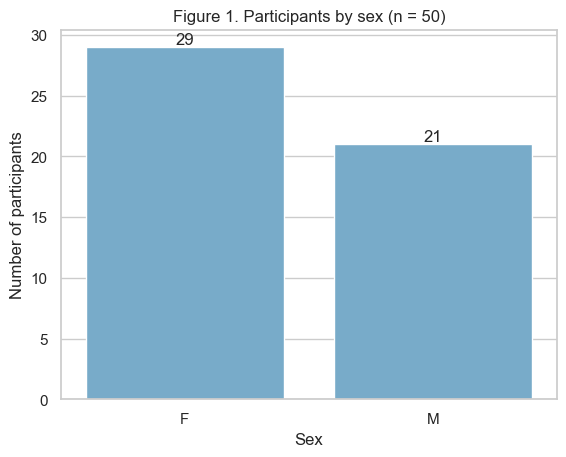

In [403]:
# Figure 1: how many men and women were screened
ax = sns.countplot(data=df, x="sex", order=["F", "M"], color=BAR_COLOUR)
ax.bar_label(ax.containers[0])
plt.title(f"Figure 1. Participants by sex (n = {len(df)})")
plt.xlabel("Sex")
plt.ylabel("Number of participants")
plt.savefig("outputs/figures/fig01_sex.png", dpi=200, bbox_inches="tight")
plt.show()

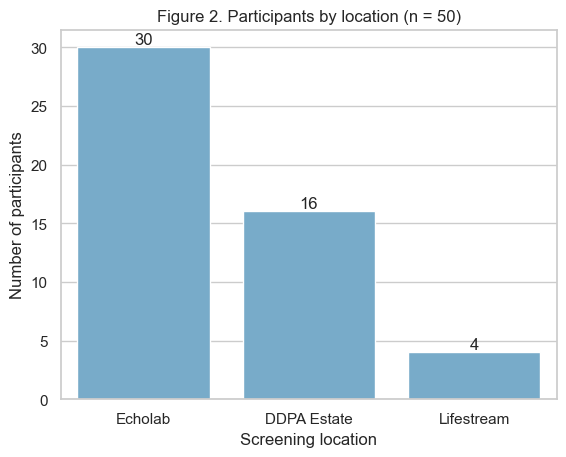

In [404]:
# Figure 2: how many participants at each location
ax = sns.countplot(data=df, x="location", order=LOCATION_ORDER, color=BAR_COLOUR)
ax.bar_label(ax.containers[0])
plt.title(f"Figure 2. Participants by location (n = {len(df)})")
plt.xlabel("Screening location")
plt.ylabel("Number of participants")
plt.savefig("outputs/figures/fig02_location.png", dpi=200, bbox_inches="tight")
plt.show()

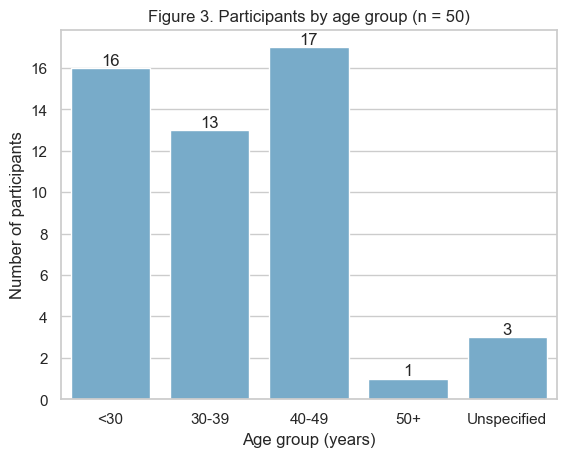

In [405]:
# Figure 3: how many participants in each age group
ax = sns.countplot(data=df, x="age_group", order=["<30", "30-39", "40-49", "50+", "Unspecified"], color=BAR_COLOUR)
ax.bar_label(ax.containers[0])
plt.title(f"Figure 3. Participants by age group (n = {len(df)})")
plt.xlabel("Age group (years)")
plt.ylabel("Number of participants")
plt.savefig("outputs/figures/fig03_age_group.png", dpi=200, bbox_inches="tight")
plt.show()

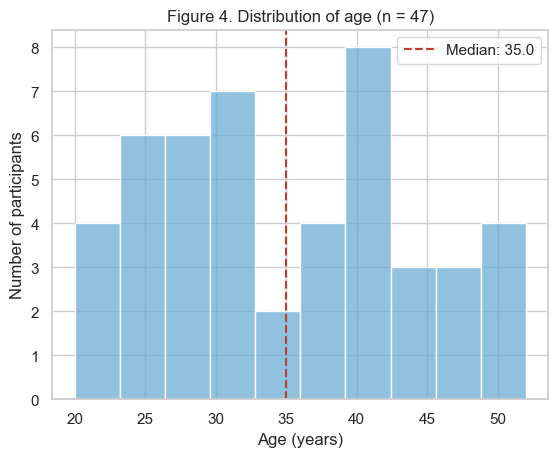

In [406]:
# Figure 4: how ages are spread out (only participants with a known age)
sns.histplot(data=df, x="age", bins=10, color=BAR_COLOUR, edgecolor="white")
plt.axvline(df["age"].median(), color="#c0392b", linestyle="--", label=f"Median: {df['age'].median():.1f}")
plt.title(f"Figure 4. Distribution of age (n = {df['age'].notna().sum()})")
plt.xlabel("Age (years)")
plt.ylabel("Number of participants")
plt.legend()
plt.savefig("outputs/figures/fig04_age.png", dpi=200, bbox_inches="tight")
plt.show()

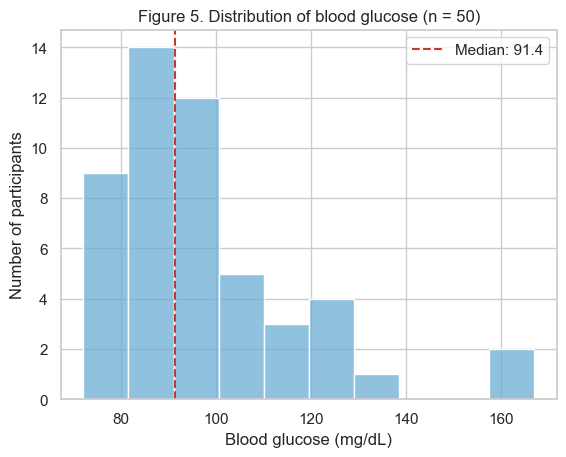

In [407]:
# Figure 5: how blood glucose is spread out
sns.histplot(data=df, x="glucose_mgdl", bins=10, color=BAR_COLOUR, edgecolor="white")
plt.axvline(df["glucose_mgdl"].median(), color="#c0392b", linestyle="--", label=f"Median: {df['glucose_mgdl'].median():.1f}")
plt.title(f"Figure 5. Distribution of blood glucose (n = {df['glucose_mgdl'].notna().sum()})")
plt.xlabel("Blood glucose (mg/dL)")
plt.ylabel("Number of participants")
plt.legend()
plt.savefig("outputs/figures/fig05_glucose.png", dpi=200, bbox_inches="tight")
plt.show()

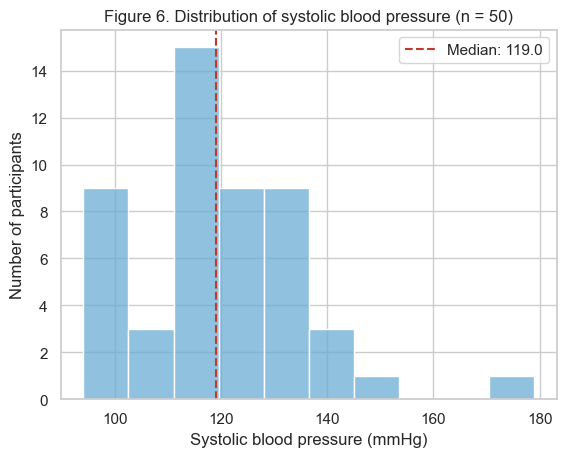

In [408]:
# Figure 6: how systolic blood pressure is spread out
sns.histplot(data=df, x="systolic_bp", bins=10, color=BAR_COLOUR, edgecolor="white")
plt.axvline(df["systolic_bp"].median(), color="#c0392b", linestyle="--", label=f"Median: {df['systolic_bp'].median():.1f}")
plt.title(f"Figure 6. Distribution of systolic blood pressure (n = {df['systolic_bp'].notna().sum()})")
plt.xlabel("Systolic blood pressure (mmHg)")
plt.ylabel("Number of participants")
plt.legend()
plt.savefig("outputs/figures/fig06_systolic.png", dpi=200, bbox_inches="tight")
plt.show()

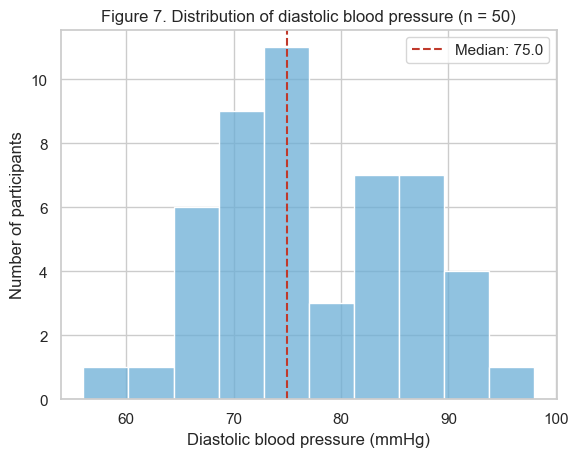

In [409]:
# Figure 7: how diastolic blood pressure is spread out
sns.histplot(data=df, x="diastolic_bp", bins=10, color=BAR_COLOUR, edgecolor="white")
plt.axvline(df["diastolic_bp"].median(), color="#c0392b", linestyle="--", label=f"Median: {df['diastolic_bp'].median():.1f}")
plt.title(f"Figure 7. Distribution of diastolic blood pressure (n = {df['diastolic_bp'].notna().sum()})")
plt.xlabel("Diastolic blood pressure (mmHg)")
plt.ylabel("Number of participants")
plt.legend()
plt.savefig("outputs/figures/fig07_diastolic.png", dpi=200, bbox_inches="tight")
plt.show()

### What Figures 1 to 7 show

- There are more women than men, and Echolab had the most participants. Lifestream had very few, so anything we say about it is weak.
- The age groups under 30, 30 to 39 and 40 to 49 are similar in size. Only one participant is 50 or older.
- Glucose has a long tail on the high side: most participants are close together and a few are much higher.
- Systolic blood pressure also has a few high values. Diastolic blood pressure is more evenly spread.
- The red dashed line is the median, a better description of a typical value when a few readings are very high.

## Bivariate analysis (two variables at a time)

Bivariate means looking at **two variables together**. First we compare a measurement between groups (sex, then location) with boxplots. Then we look at pairs of numbers with scatter plots.

How to read a boxplot: the box covers the middle half of the values (Q1 to Q3), the line inside is the median, and the whiskers reach the lowest and highest typical values. Every dot is one participant. The number of participants (n) is shown under each group.

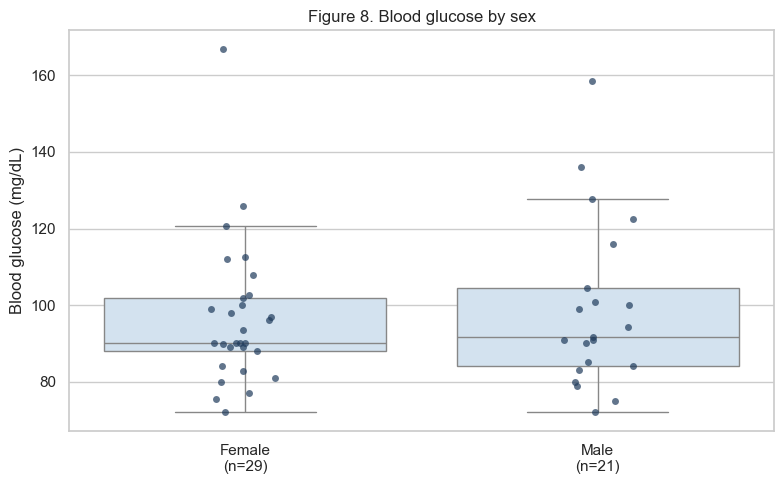

In [410]:
# Figure 8: Blood glucose for women and men

n = df["sex"].value_counts()

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="glucose_mgdl",
    order=["F", "M"],
    color="#cfe2f3",
    showfliers=False
)

sns.stripplot(
    data=df,
    x="sex",
    y="glucose_mgdl",
    order=["F", "M"],
    color="#1f3b5c",
    alpha=0.7
)

plt.xticks(
    [0, 1],
    [f"Female\n(n={n['F']})", f"Male\n(n={n['M']})"]
)

plt.title("Figure 8. Blood glucose by sex")
plt.xlabel("")
plt.ylabel("Blood glucose (mg/dL)")

plt.tight_layout()

plt.savefig(
    "outputs/figures/fig08_glucose_by_sex.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

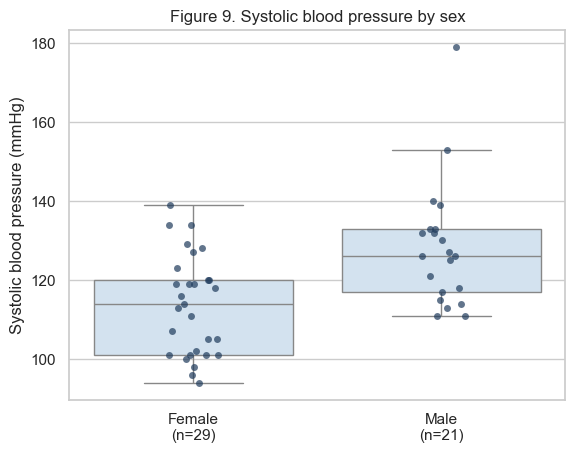

In [411]:
# Figure 9: systolic blood pressure for women and men
n = df["sex"].value_counts()
sns.boxplot(data=df, x="sex", y="systolic_bp", order=["F", "M"], color="#cfe2f3", showfliers=False)
sns.stripplot(data=df, x="sex", y="systolic_bp", order=["F", "M"], color="#1f3b5c", alpha=0.7)
plt.xticks([0, 1], [f"Female\n(n={n['F']})", f"Male\n(n={n['M']})"])
plt.title("Figure 9. Systolic blood pressure by sex")
plt.xlabel("")
plt.ylabel("Systolic blood pressure (mmHg)")
plt.savefig("outputs/figures/fig09_systolic_by_sex.png", dpi=200, bbox_inches="tight")
plt.show()

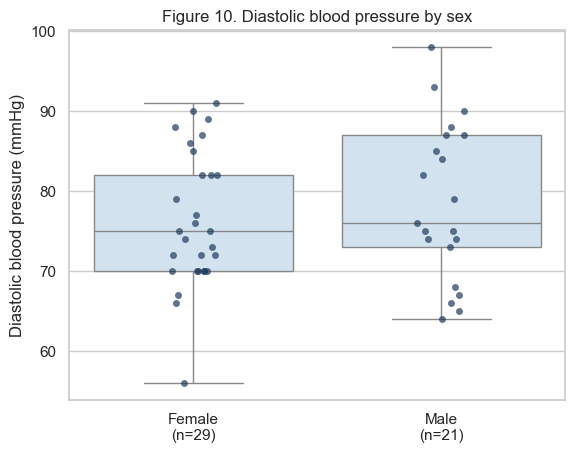

In [412]:
# Figure 10: diastolic blood pressure for women and men
n = df["sex"].value_counts()
sns.boxplot(data=df, x="sex", y="diastolic_bp", order=["F", "M"], color="#cfe2f3", showfliers=False)
sns.stripplot(data=df, x="sex", y="diastolic_bp", order=["F", "M"], color="#1f3b5c", alpha=0.7)
plt.xticks([0, 1], [f"Female\n(n={n['F']})", f"Male\n(n={n['M']})"])
plt.title("Figure 10. Diastolic blood pressure by sex")
plt.xlabel("")
plt.ylabel("Diastolic blood pressure (mmHg)")
plt.savefig("outputs/figures/fig10_diastolic_by_sex.png", dpi=200, bbox_inches="tight")
plt.show()

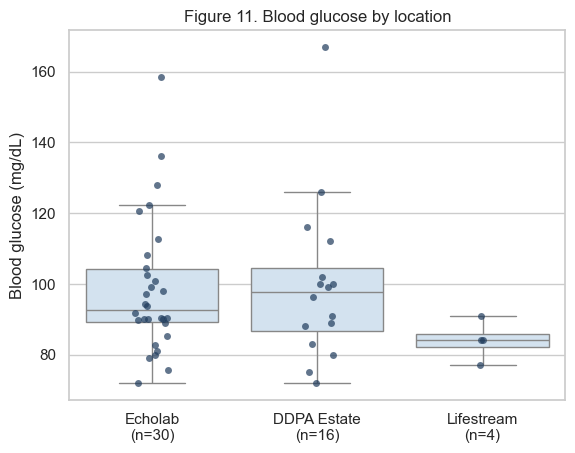

In [413]:
# Figure 11: blood glucose at each location
n = df["location"].value_counts()
sns.boxplot(data=df, x="location", y="glucose_mgdl", order=LOCATION_ORDER, color="#cfe2f3", showfliers=False)
sns.stripplot(data=df, x="location", y="glucose_mgdl", order=LOCATION_ORDER, color="#1f3b5c", alpha=0.7)
plt.xticks(range(3), [f"{loc}\n(n={n[loc]})" for loc in LOCATION_ORDER])
plt.title("Figure 11. Blood glucose by location")
plt.xlabel("")
plt.ylabel("Blood glucose (mg/dL)")
plt.savefig("outputs/figures/fig11_glucose_by_location.png", dpi=200, bbox_inches="tight")
plt.show()

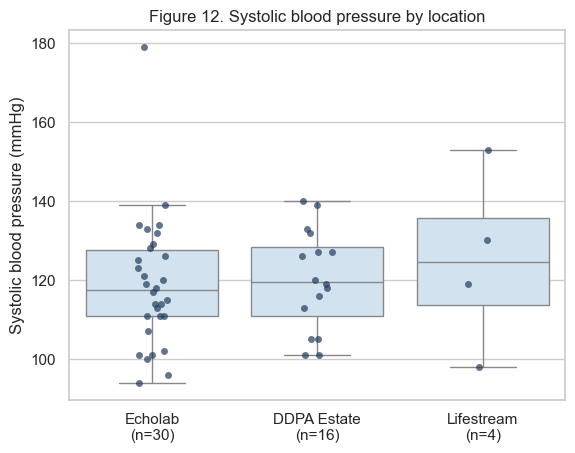

In [414]:
# Figure 12: systolic blood pressure at each location
n = df["location"].value_counts()
sns.boxplot(data=df, x="location", y="systolic_bp", order=LOCATION_ORDER, color="#cfe2f3", showfliers=False)
sns.stripplot(data=df, x="location", y="systolic_bp", order=LOCATION_ORDER, color="#1f3b5c", alpha=0.7)
plt.xticks(range(3), [f"{loc}\n(n={n[loc]})" for loc in LOCATION_ORDER])
plt.title("Figure 12. Systolic blood pressure by location")
plt.xlabel("")
plt.ylabel("Systolic blood pressure (mmHg)")
plt.savefig("outputs/figures/fig12_systolic_by_location.png", dpi=200, bbox_inches="tight")
plt.show()

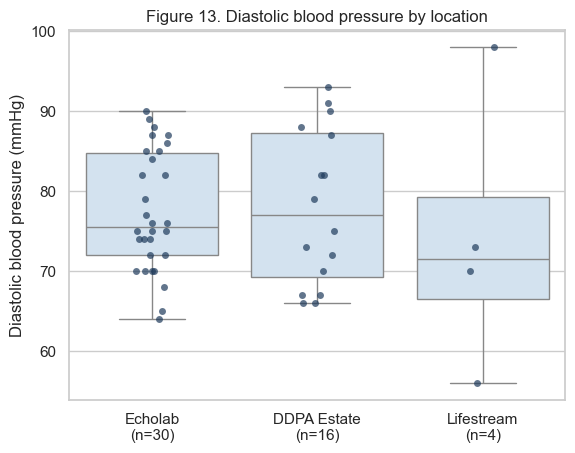

In [415]:
# Figure 13: diastolic blood pressure at each location
n = df["location"].value_counts()
sns.boxplot(data=df, x="location", y="diastolic_bp", order=LOCATION_ORDER, color="#cfe2f3", showfliers=False)
sns.stripplot(data=df, x="location", y="diastolic_bp", order=LOCATION_ORDER, color="#1f3b5c", alpha=0.7)
plt.xticks(range(3), [f"{loc}\n(n={n[loc]})" for loc in LOCATION_ORDER])
plt.title("Figure 13. Diastolic blood pressure by location")
plt.xlabel("")
plt.ylabel("Diastolic blood pressure (mmHg)")
plt.savefig("outputs/figures/fig13_diastolic_by_location.png", dpi=200, bbox_inches="tight")
plt.show()

### What Figures 8 to 13 show

- **Sex:** systolic blood pressure appears higher in men than in women in this group. Glucose and diastolic pressure look similar. The groups have different sizes and different age mixes (all three participants with no recorded age are men), so this is a description, not a finding about men and women in general.
- **Location:** the differences between locations are small compared with the spread inside each location. Lifestream has only 4 participants, so its box is not reliable.
- **Why we must be careful:** the people at each location were not chosen at random, and the age mix differs between locations. The screening also took place on different days. A difference between locations could come from who attended, not from the place itself.
- These are descriptions only. Part 2 adds confidence intervals and cautious comparisons.

In [416]:
SEX_COLOURS = {
    "F": "#d98ba3",
    "M": "#1f3b5c"
}

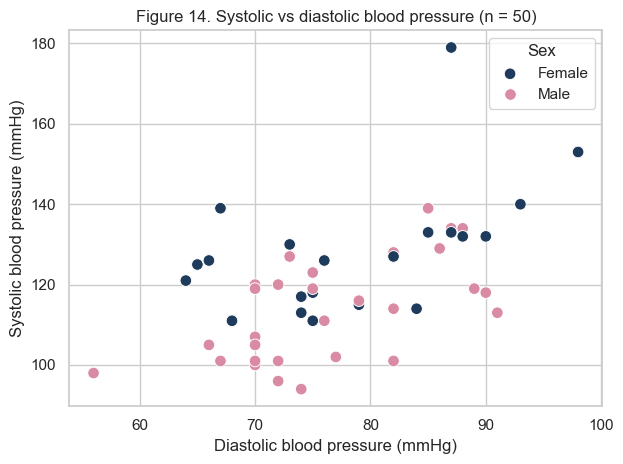

In [417]:
# Figure 14: Do systolic and diastolic blood pressure rise together?

data = df.dropna(subset=["diastolic_bp", "systolic_bp"])

sns.scatterplot(
    data=data,
    x="diastolic_bp",
    y="systolic_bp",
    hue="sex",
    palette=SEX_COLOURS,
    hue_order=["F", "M"],
    s=70
)

plt.title(f"Figure 14. Systolic vs diastolic blood pressure (n = {len(data)})")
plt.xlabel("Diastolic blood pressure (mmHg)")
plt.ylabel("Systolic blood pressure (mmHg)")
plt.legend(title="Sex", labels=["Female", "Male"])
plt.tight_layout()

plt.savefig(
    "outputs/figures/fig14_systolic_vs_diastolic.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

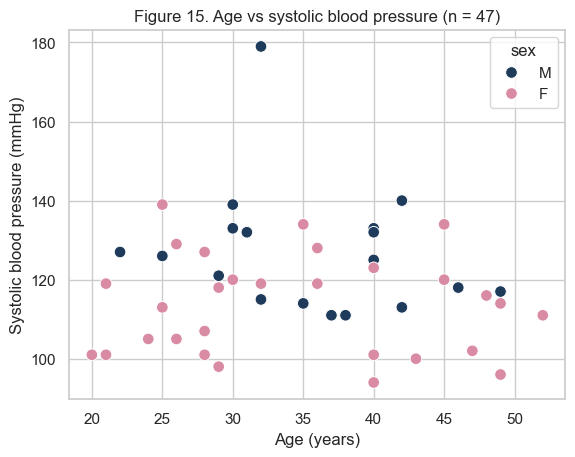

In [418]:
# Figure 15: does systolic blood pressure change with age? (participants with a known age only)
data = df.dropna(subset=["age", "systolic_bp"])
sns.scatterplot(data=data, x="age", y="systolic_bp", hue="sex", palette=SEX_COLOURS, s=70)
plt.title(f"Figure 15. Age vs systolic blood pressure (n = {len(data)})")
plt.xlabel("Age (years)")
plt.ylabel("Systolic blood pressure (mmHg)")
plt.savefig("outputs/figures/fig15_age_vs_systolic.png", dpi=200, bbox_inches="tight")
plt.show()

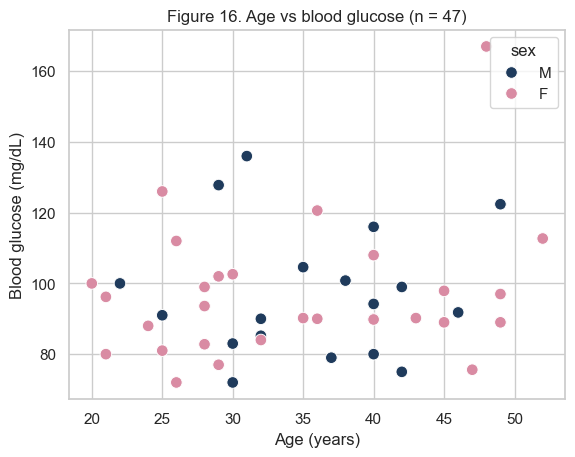

In [419]:
# Figure 16: does blood glucose change with age? (participants with a known age only)
data = df.dropna(subset=["age", "glucose_mgdl"])
sns.scatterplot(data=data, x="age", y="glucose_mgdl", hue="sex", palette=SEX_COLOURS, s=70)
plt.title(f"Figure 16. Age vs blood glucose (n = {len(data)})")
plt.xlabel("Age (years)")
plt.ylabel("Blood glucose (mg/dL)")
plt.savefig("outputs/figures/fig16_age_vs_glucose.png", dpi=200, bbox_inches="tight")
plt.show()

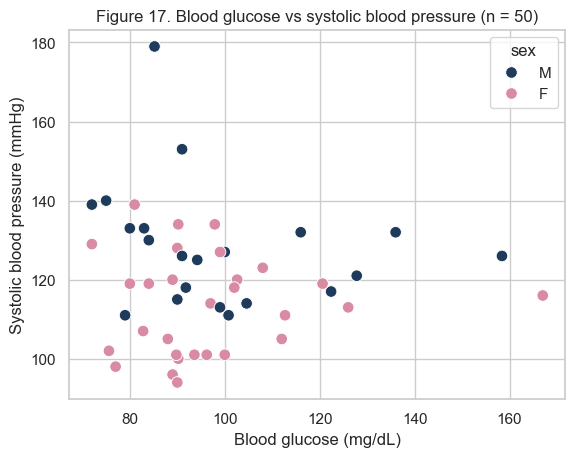

In [420]:
# Figure 17: is blood glucose related to systolic blood pressure?
data = df.dropna(subset=["glucose_mgdl", "systolic_bp"])
sns.scatterplot(data=data, x="glucose_mgdl", y="systolic_bp", hue="sex", palette=SEX_COLOURS, s=70)
plt.title(f"Figure 17. Blood glucose vs systolic blood pressure (n = {len(data)})")
plt.xlabel("Blood glucose (mg/dL)")
plt.ylabel("Systolic blood pressure (mmHg)")
plt.savefig("outputs/figures/fig17_glucose_vs_systolic.png", dpi=200, bbox_inches="tight")
plt.show()

### What Figures 14 to 17 show

- Systolic and diastolic blood pressure rise together. That is expected, because they are two numbers from the same reading.
- Age against blood pressure, age against glucose, and glucose against blood pressure show no obvious pattern. The dots look scattered.
- The age charts use only the 47 participants with a known age. The three "Ad" participants are not hidden: they are left out of these charts, and the title says n.
- With about 50 points, a weak pattern could be hidden and an apparent pattern could be chance.

## Multivariate analysis (several variables together)

Multivariate means looking at **three or more variables at once**. In the next chart, systolic blood pressure is plotted against age, the colour shows sex, and the shape shows location. Because we split 47 people into many small groups, the chart is for looking, not for drawing conclusions.

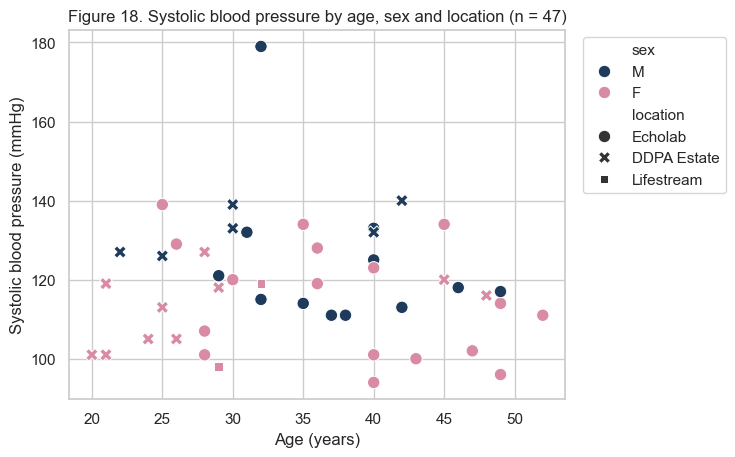

In [421]:
# Figure 18: systolic blood pressure by age, sex (colour) and location (shape)
data = df.dropna(subset=["age"])
sns.scatterplot(data=data, x="age", y="systolic_bp", hue="sex", style="location", palette=SEX_COLOURS, s=80)
plt.title(f"Figure 18. Systolic blood pressure by age, sex and location (n = {len(data)})")
plt.xlabel("Age (years)")
plt.ylabel("Systolic blood pressure (mmHg)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig("outputs/figures/fig18_age_sex_location.png", dpi=200, bbox_inches="tight")
plt.show()

### What Figure 18 shows

Age, sex and location overlap: for example, the younger participants are mostly at one location. With so few points for each combination, no pattern can be trusted. This chart shows why group comparisons in this dataset need caution.

## Correlation

A **correlation** is one number between −1 and +1 that says how closely two variables move together:

- Near **+1**: when one goes up, the other tends to go up.
- Near **−1**: when one goes up, the other tends to go down.
- Near **0**: no clear straight-line relationship.

We use **Spearman** correlation. It works on ranks, so a few extreme readings do not distort it, which suits a small dataset. The table of all pairs is called a correlation matrix.

In [422]:
# Correlation matrix (Spearman): every pair of numeric variables
corr = df[["age", "glucose_mgdl", "systolic_bp", "diastolic_bp"]].corr(method="spearman")
corr.round(2)

,age,glucose_mgdl,systolic_bp,diastolic_bp
age,1.00,0.09,-0.06,0.11
glucose_mgdl,0.09,1.00,-0.09,0.17
systolic_bp,-0.06,-0.09,1.00,0.49
diastolic_bp,0.11,0.17,0.49,1.00


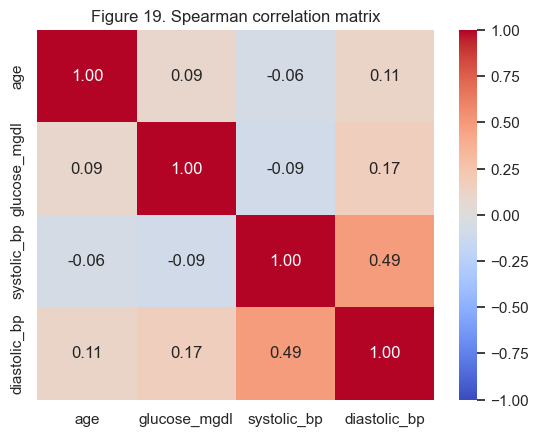

In [423]:
# Figure 19: the same correlation matrix as a heatmap
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Figure 19. Spearman correlation matrix")
plt.savefig("outputs/figures/fig19_correlation_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

### What the correlations show

- The only moderate relationship is between systolic and diastolic blood pressure, which is expected because they come from the same reading.
- Every other pair is close to zero, which means no clear straight-line relationship in this group.
- With 47 to 50 participants, correlations are unstable, and we have not measured how uncertain they are. Confidence intervals come in Part 2.
- A correlation, even a strong one, never shows that one thing causes another. A value near zero does not prove there is no relationship, only that none is clearly visible here.

## Ethics, limitations and summary

### Privacy

- Names were replaced with pseudonymised IDs. This is not full anonymisation: with 50 people, exact dates and locations.
- No names, phone numbers or addresses appear in this notebook.
- The real data file and `outputs/participants_clean.csv` hold participant-level records. 
### Data protection

The Nigeria Data Protection Act 2023 sets principles that apply to this kind of data, including lawful and fair processing, purpose limitation, data minimisation, security and accountability, and it treats health data as sensitive. Replacing names with codes is one safeguard, not proof of compliance. This notebook is not legal advice and does not claim full legal compliance.

### Responsible use

This is an educational and analytical project. It is not medical advice, not a diagnostic tool and has not been clinically validated. A raised screening reading is a reason to see a health professional, not a diagnosis.

### Limitations

| Limitation | Consequence |
|---|---|
| Convenience sample of 50 people who chose to attend | Cannot say how common high BP or glucose is in the community |
| Fasting and random glucose not distinguished | No fasting-based cut-offs can be used, and nobody can be classed as diabetic |
| Glucose unit taken from the column heading | Confirm against field records |
| Location, date and attendees are linked, and age differs by location | Differences between sites cannot be separated from who attended |
| Very small groups (Lifestream has 4 people, one participant is 50 or older) | Results for those groups are unreliable |
| Three participants have no exact age | Left out of age-based calculations and charts only |
| No weight, height, medication, medical history or family history | Important risk factors are missing |

In [424]:
# A plain-language summary, written by the code from the data (so it always matches the data)
age_known = df["age"].dropna()
print("PLAIN-LANGUAGE SUMMARY (generated from the data)")
print("-", len(df), "participants were screened at", df["location"].nunique(), "locations on", df["screening_date"].nunique(), "days.")
print("-", (df["sex"] == "F").sum(), "female and", (df["sex"] == "M").sum(), "male.")
print("- Age: median", round(age_known.median()), "years, range", int(age_known.min()), "to", int(age_known.max()), ";", df["age_unspecified"].sum(), "participants have no exact age.")
print("- Blood glucose: median", round(df["glucose_mgdl"].median(), 1), "mg/dL, range", int(df["glucose_mgdl"].min()), "to", int(df["glucose_mgdl"].max()))
print("- Systolic BP: median", round(df["systolic_bp"].median()), "mmHg, range", int(df["systolic_bp"].min()), "to", int(df["systolic_bp"].max()))
print("- Diastolic BP: median", round(df["diastolic_bp"].median()), "mmHg, range", int(df["diastolic_bp"].min()), "to", int(df["diastolic_bp"].max()))
print("- These results describe this screening group only. They are not diagnoses.")

PLAIN-LANGUAGE SUMMARY (generated from the data)
- 50 participants were screened at 3 locations on 4 days.
- 29 female and 21 male.
- Age: median 35 years, range 20 to 52 ; 3 participants have no exact age.
- Blood glucose: median 91.4 mg/dL, range 72 to 167
- Systolic BP: median 119 mmHg, range 94 to 179
- Diastolic BP: median 75 mmHg, range 56 to 98
- These results describe this screening group only. They are not diagnoses.


## PART 2: Statistics and Data Management for a 50-Participant Blood Pressure and Blood Glucose Screening

Part 1 prepared the data and described it. Part 2 answers two further questions:

1. **Statistics:** how uncertain are the numbers, and are the differences between groups bigger than chance could produce?
2. **Data management:** is the dataset documented, checked and stored well enough that someone else could understand, trust and reuse it without seeing any real participant record?

## Research questions

1. How uncertain are the descriptive numbers (means, medians, percentages)?
2. Do men and women, or the three locations, differ in blood pressure or blood glucose, and does age explain any difference?
3. What share of participants had readings in each blood pressure and glucose band, and how uncertain is that share?
4. Is the dataset documented with a data dictionary, a schema, quality checks, a file fingerprint and a reduced-disclosure summary?

### Setup for Part 2

This notebook already contains the cleaned dataset from Part 1, including all 50 participants and the derived age group and pulse pressure columns.

The following libraries are already available from Part 1:
- pandas
- numpy
- matplotlib
- seaborn
- pathlib

Part 2 introduces SciPy for statistical analysis and numerical optimisation.

Specifically:
- `scipy.stats` provides statistical tests and probability distributions.
- `scipy.optimize.brentq` is used to calculate the minimum detectable standardised mean difference for the sample-size sensitivity analysis.

In [425]:
# Part 2: Additional statistical tools
from scipy import stats
from scipy.optimize import brentq

In [426]:
# Create a folder for the documentation files made in this part (nothing happens if it already exists)
Path("docs").mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 80)

In [427]:
# Check that the table from Part 1 is in memory
print("The table has", df.shape[0], "participants and", df.shape[1], "columns")

The table has 50 participants and 12 columns


# Mathematics, Probability and Statistics

## Study Design and Causal Reasoning

Before conducting statistical tests, it is important to establish the study design and understand how the measurements were obtained. These factors determine how the results should be interpreted and what conclusions can reasonably be drawn.

- **Study design:** This was a cross-sectional community-based screening exercise. Participants were assessed during the screening period, providing a snapshot of their recorded health measurements rather than a longitudinal assessment of changes in their health over time.

- **Sampling method:** A convenience sampling approach was used. Participants were individuals who were accessible and willing to take part in the screening. They were not randomly selected from the wider population; therefore, the findings cannot be assumed to represent the entire community.

- **Measurement procedure:** Blood pressure and blood glucose measurements were collected during the screening exercise. Where an initially elevated reading was obtained, some participants underwent repeat measurements at subsequent time intervals. In these instances, a subsequent reading considered more suitable for recording was retained in the dataset. Consequently, the dataset contains one recorded value per participant for each measurement, but this does not mean that every participant was measured only once.

- **Measurement limitations:** The original and intermediate readings were not consistently retained for all repeat measurements. Therefore, the analysis cannot reconstruct the full measurement sequence, compare initial and subsequent readings, or independently establish the degree of variation between repeated measurements. The selection of a subsequent reading may also influence the distribution of recorded values, particularly if readings closer to the expected range were preferentially retained.

- **Potential confounding:** A confounder is a factor associated with both a group characteristic and an outcome that may distort an observed relationship. In this screening exercise, age, sex, screening location and screening day may contribute to differences in the observed measurements. Because participants were not randomly assigned to locations or groups, these factors should be considered when interpreting comparisons.

- **Causal interpretation:** This was an observational screening exercise, not a randomised experiment. Differences between groups or locations can therefore be described as observed associations or differences, not evidence that one factor caused another.

The following analyses examine the distribution of participant characteristics across screening locations to provide context for interpreting the observed differences in measurements.

In [428]:
# Median age at each location (known ages only)
df.groupby("location", observed=True)["age"].agg(["count", "median", "min", "max"])

,count,median,min,max
location,,,,
DDPA Estate,16,27.0,20.0,48.0
Echolab,29,38.0,25.0,52.0
Lifestream,2,30.5,29.0,32.0


In [429]:
# How many men and women at each location?
pd.crosstab(df["location"], df["sex"], margins=True)

sex,F,M,All
location,,,
DDPA Estate,10,6,16
Echolab,17,13,30
Lifestream,2,2,4
All,29,21,50


### What the study-design tables show

- The median age at DDPA Estate is much lower than at Echolab, and one location has too few participants with a known age to compare. So the locations are **not comparable groups**: a difference between locations could come from age, not place.
- The mix of men and women is similar across locations, so sex is less tangled with location than age is.
- Everything that follows is therefore a description of associations in these 50 people. It is not evidence about causes.

##  Descriptive statistics and probability distributions

**Descriptive statistics** summarise the people we measured. **Inferential statistics** use that sample to say something, with stated uncertainty, about what might hold beyond it.

A **probability distribution** describes how likely different values are. Many tests assume the values follow a **normal distribution**: a symmetric bell shape. We check this, because it decides which tests are reliable.

New measures in the next table:

- **Skewness:** 0 means symmetric. A positive value means a long tail of high values.
- **CV (coefficient of variation):** the standard deviation as a percentage of the mean. It compares spread between variables with different units.

In [430]:
# Extended descriptive statistics for every numeric variable
numeric_cols = ["age", "glucose_mgdl", "systolic_bp", "diastolic_bp", "pulse_pressure"]

desc = df[numeric_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
desc["Q1"] = df[numeric_cols].quantile(0.25)
desc["Q3"] = df[numeric_cols].quantile(0.75)
desc["IQR"] = desc["Q3"] - desc["Q1"]
desc["skewness"] = df[numeric_cols].skew()
desc["CV_percent"] = desc["std"] / desc["mean"] * 100
desc.round(2)

,count,mean,median,std,min,max,Q1,Q3,IQR,skewness,CV_percent
age,47.0,34.83,35.0,8.82,20.0,52.0,28.00,41.00,13.00,0.17,25.32
glucose_mgdl,50.0,97.69,91.4,19.96,72.0,167.0,84.30,102.45,18.15,1.60,20.43
systolic_bp,50.0,119.78,119.0,15.75,94.0,179.0,111.00,128.75,17.75,1.05,13.15
diastolic_bp,50.0,77.32,75.0,9.04,56.0,98.0,70.00,85.00,15.00,0.16,11.69
pulse_pressure,50.0,42.46,43.0,13.32,19.0,92.0,34.25,48.00,13.75,0.99,31.37


In [431]:
# Shapiro-Wilk test of normality for each numeric variable (p below 0.05 = clearly not normal)
rows = []
for col in numeric_cols:
    w, p = stats.shapiro(df[col].dropna())
    rows.append([col, w, p, "no clear departure from normal" if p >= 0.05 else "departs from normal"])

pd.DataFrame(rows, columns=["variable", "W", "p_value", "reading"]).round(4)

,variable,W,p_value,reading
0,age,0.9591,0.0994,no clear departure from normal
1,glucose_mgdl,0.8658,0.0000,departs from normal
2,systolic_bp,0.9343,0.0080,departs from normal
3,diastolic_bp,0.9730,0.3049,no clear departure from normal
4,pulse_pressure,0.9405,0.0141,departs from normal


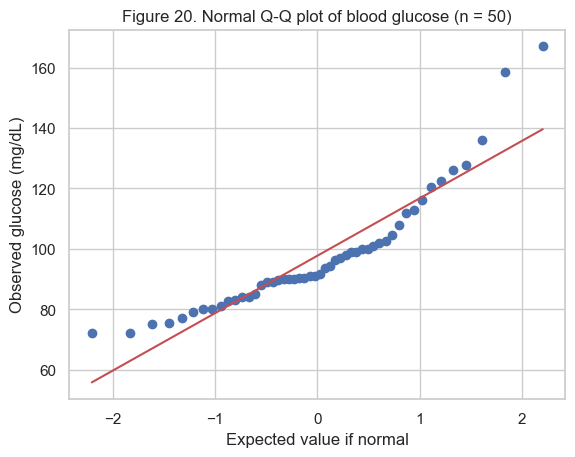

In [432]:
# Figure 20: Q-Q plot for blood glucose (dots close to the line = normal-shaped)
stats.probplot(df["glucose_mgdl"], dist="norm", plot=plt)
plt.title("Figure 20. Normal Q-Q plot of blood glucose (n = 50)")
plt.xlabel("Expected value if normal")
plt.ylabel("Observed glucose (mg/dL)")
plt.savefig("outputs/figures/fig20_qq_glucose.png", dpi=200, bbox_inches="tight")
plt.show()

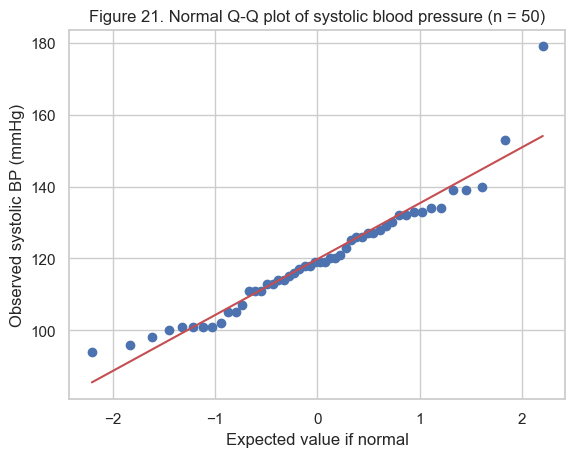

In [433]:
# Figure 21: Q-Q plot for systolic blood pressure
stats.probplot(df["systolic_bp"], dist="norm", plot=plt)
plt.title("Figure 21. Normal Q-Q plot of systolic blood pressure (n = 50)")
plt.xlabel("Expected value if normal")
plt.ylabel("Observed systolic BP (mmHg)")
plt.savefig("outputs/figures/fig21_qq_systolic.png", dpi=200, bbox_inches="tight")
plt.show()

### What the distribution checks show

- **Blood glucose, systolic blood pressure and pulse pressure** showed statistically significant departures from normality based on the Shapiro-Wilk test (p < 0.05).
- **Age and diastolic blood pressure** showed no statistically significant evidence of departure from normality (p > 0.05).
- Normality tests have limitations, particularly with relatively small samples. Therefore, their results should be interpreted alongside histograms, Q-Q plots and skewness measures.
- **Statistical approach:** Normality checks were treated as diagnostic information rather than an automatic rule for selecting statistical tests. Medians and interquartile ranges were used to describe distributions, with non-parametric methods used for group comparisons where appropriate. Welch's t-test was also reported as a supplementary comparison to assess the sensitivity of findings to the choice of statistical method.

## Sampling and uncertainty

Our 50 people are one possible sample. If the screening were repeated with different people, every mean and median would come out a little different. **Sampling uncertainty** is how much a number would move from sample to sample. The **standard error** measures that movement.

We cannot repeat the screening, but we can imitate it with the **bootstrap**:

1. Draw 50 people *with replacement* from our 50 people (some appear twice, some not at all).
2. Calculate the median of that new sample.
3. Repeat 10,000 times.

The spread of the 10,000 medians shows how much the median is likely to move. The bootstrap needs no assumption about a normal shape, which suits skewed glucose values. A fixed random seed (42) makes the results repeatable. **What the bootstrap cannot do:** it shows how much a number would vary because of the luck of who is in a sample of this size. It does not fix selection bias (who chose to attend), it does not make the 50 people representative of the community, and in a small sample its 95% intervals are approximate, not exact.

*The bootstrap approximates sampling variability using the observed sample as an empirical representation of the underlying distribution. Its reliability therefore depends on the quality and representativeness of the original sample.*

In [434]:
# Bootstrap: resample the 50 glucose values with replacement 10,000 times and take the median each time
rng = np.random.default_rng(42)
glucose = df["glucose_mgdl"].to_numpy()
boot_medians = np.array([np.median(rng.choice(glucose, size=len(glucose), replace=True)) for _ in range(10000)])
print("Observed median:", np.median(glucose), "| bootstrap standard error of the median:", round(boot_medians.std(), 2))

Observed median: 91.4 | bootstrap standard error of the median: 2.69


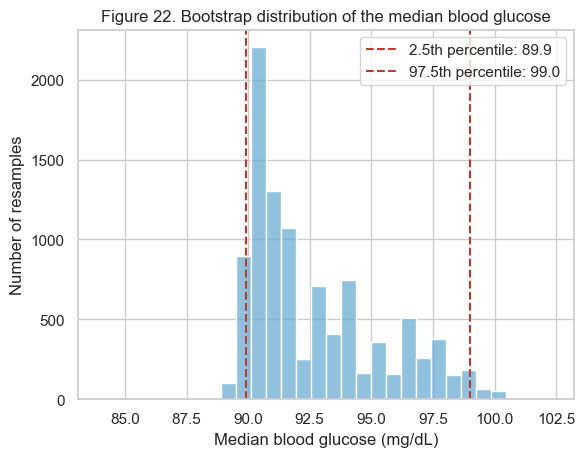

In [435]:
# Figure 22: how much the median glucose would move if the screening could be repeated
low, high = np.percentile(boot_medians, [2.5, 97.5])
sns.histplot(boot_medians, bins=30, color=BAR_COLOUR, edgecolor="white")
plt.axvline(low, color="#c0392b", linestyle="--", label=f"2.5th percentile: {low:.1f}")
plt.axvline(high, color="#c0392b", linestyle="--", label=f"97.5th percentile: {high:.1f}")
plt.title("Figure 22. Bootstrap distribution of the median blood glucose")
plt.xlabel("Median blood glucose (mg/dL)")
plt.ylabel("Number of resamples")
plt.legend()
plt.savefig("outputs/figures/fig22_bootstrap_median.png", dpi=200, bbox_inches="tight")
plt.show()

### What Figure 22 shows

The histogram displays the distribution of 10,000 bootstrap estimates of the median blood glucose level. The distribution shows some asymmetry, extending further above the observed median than below it.

The two red dashed lines mark the 2.5th and 97.5th percentiles (89.9 and 99.9 mg/dL, respectively). Together, they define the middle 95% of the bootstrap distribution, giving a 95% percentile bootstrap confidence interval for the median.

The observed median of 91.4 mg/dL falls within this interval.

This interval describes the uncertainty estimated through resampling the observed participants. It does not correct for convenience sampling or establish that the results represent the wider community.

## 2.4 Confidence intervals

A **95% confidence interval** is a range built so that, if the whole screening could be repeated many times and an interval built each time, about 95 of every 100 intervals would contain the true value. It shows how precisely we know a number. A narrow interval means a precise number. A wide interval means we know little.

It does **not** say there is a 95% chance that the true value is in this one interval, and it only speaks for people like those who attend this kind of screening, not for the whole community. An interval cannot repair a biased sample: if the people who attended are unlike everyone else, the interval is precise but wrong about the community. In a sample this small, the stated 95% of the bootstrap and Wilson intervals is also approximate.

We use three methods, each matched to the kind of number:

| Number | Method | Why |
|---|---|---|
| A mean | t interval | Standard method, reliable when the shape is not too skewed |
| A median | Bootstrap percentile interval | Needs no normal shape, suits skewed glucose |
| A percentage | Wilson interval | Behaves well for small samples and for percentages near 0% or 100% |

In [436]:
# 95% confidence interval for the MEAN of each variable (t distribution)
rows = []
for col in numeric_cols:
    x = df[col].dropna()
    low, high = stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))
    rows.append([col, len(x), x.mean(), stats.sem(x), low, high])

mean_ci = pd.DataFrame(rows, columns=["variable", "n", "mean", "std_error", "ci_low", "ci_high"])
mean_ci.round(2)

,variable,n,mean,std_error,ci_low,ci_high
0,age,47,34.83,1.29,32.24,37.42
1,glucose_mgdl,50,97.69,2.82,92.02,103.36
2,systolic_bp,50,119.78,2.23,115.30,124.26
3,diastolic_bp,50,77.32,1.28,74.75,79.89
4,pulse_pressure,50,42.46,1.88,38.67,46.25


In [437]:
# 95% bootstrap confidence interval for the MEDIAN of each variable
rng = np.random.default_rng(42)
rows = []
for col in numeric_cols:
    x = df[col].dropna().to_numpy()
    boots = np.array([np.median(rng.choice(x, size=len(x), replace=True)) for _ in range(10000)])
    low, high = np.percentile(boots, [2.5, 97.5])
    rows.append([col, len(x), np.median(x), low, high])

median_ci = pd.DataFrame(rows, columns=["variable", "n", "median", "ci_low", "ci_high"])
median_ci.round(2)

,variable,n,median,ci_low,ci_high
0,age,47,35.0,30.0,40.0
1,glucose_mgdl,50,91.4,89.9,99.0
2,systolic_bp,50,119.0,114.0,125.0
3,diastolic_bp,50,75.0,73.0,82.0
4,pulse_pressure,50,43.0,37.0,46.0


### Reading bands and their sources

To describe how participants' blood pressure and blood glucose measurements were distributed, we grouped the recorded values into bands. The blood pressure bands follow the 2017 ACC/AHA guideline. The glucose bands use numerical cut-offs drawn from ADA fasting plasma glucose criteria, but are treated only as descriptive groupings because participants' fasting status is unknown. **These bands describe recorded measurements; they do not establish diagnoses.**

**Blood pressure** (2017 ACC/AHA guideline, Whelton *et al.*):

| Band used here | Systolic (mmHg) | | Diastolic (mmHg) |
|---|---:|---|---:|
| Normal range | Below 120 | and | Below 80 |
| Elevated range | 120–129 | and | Below 80 |
| Stage 1 range | 130–139 | or | 80–89 |
| Stage 2 range | 140 or above | or | 90 or above |

The guideline recommends classifying blood pressure using the average of at least two readings obtained on at least two separate occasions. In this dataset, one recorded value per participant is available for analysis. Some participants had repeat measurements, and a subsequent reading considered more suitable for recording was retained. The complete sequence of readings is not available for every participant. Therefore, these categories are used to describe the ranges of the recorded values, not to diagnose hypertension. Other guidelines, such as the 2024 European guideline, use different thresholds, so these categories represent one guideline-based approach rather than a universal standard.

**Blood glucose** (American Diabetes Association, *Standards of Care in Diabetes—2025*):

For fasting plasma glucose, the ADA defines below 100 mg/dL as normal, 100–125 mg/dL as the prediabetes range, and 126 mg/dL or above as the diabetes range, subject to the applicable diagnostic confirmation requirements. A random plasma glucose of 200 mg/dL or above is a diagnostic criterion when accompanied by classic symptoms of hyperglycaemia or a hyperglycaemic crisis.

However, participants' fasting status was not consistently established. Therefore, the glucose values are grouped into three numerical bands: below 100 mg/dL, 100 to below 126 mg/dL, and 126 mg/dL or above. These are **descriptive numerical groupings, not ADA clinical classifications**. No participant is labelled as having normal glucose, prediabetes or diabetes on the basis of these bands.

In [438]:
# Reading bands for blood pressure (2017 ACC/AHA categories). One reading cannot diagnose, so we say "range".
conditions = [
    (df["systolic_bp"] >= 140) | (df["diastolic_bp"] >= 90),
    (df["systolic_bp"] >= 130) | (df["diastolic_bp"] >= 80),
    (df["systolic_bp"] >= 120),
]
labels = ["Stage 2 range", "Stage 1 range", "Elevated range"]
df["bp_band"] = np.select(conditions, labels, default="Normal range")

bp_order = ["Normal range", "Elevated range", "Stage 1 range", "Stage 2 range"]
df["bp_band"].value_counts().reindex(bp_order, fill_value=0)

bp_band
Normal range      21
Elevated range     8
Stage 1 range     15
Stage 2 range      6
Name: count, dtype: int64

In [439]:
# Descriptive blood glucose bands (not clinical classifications).
# Fasting status is unknown, so these are numerical groupings only.

df["glucose_band"] = pd.cut(
    df["glucose_mgdl"],
    bins=[0, 100, 126, np.inf],
    right=False,
    labels=["Below 100", "100 to below 126", "126 and above"]
)

glucose_order = [
    "Below 100",
    "100 to below 126",
    "126 and above"
]

df["glucose_band"].value_counts().reindex(glucose_order, fill_value=0)

glucose_band
Below 100           33
100 to below 126    12
126 and above        5
Name: count, dtype: int64

In [440]:
# 95% Wilson confidence interval for each percentage (how sure are we about these shares?)
rows = []
for var, order in [("bp_band", bp_order), ("glucose_band", glucose_order)]:
    counts = df[var].value_counts().reindex(order, fill_value=0)
    for band, k in counts.items():
        ci = stats.binomtest(int(k), len(df)).proportion_ci(confidence_level=0.95, method="wilson")
        rows.append([var, band, int(k), len(df), k / len(df) * 100, ci.low * 100, ci.high * 100])

band_ci = pd.DataFrame(rows, columns=["variable", "band", "count", "n", "percent", "ci_low_percent", "ci_high_percent"])
band_ci.round(1)

,variable,band,count,n,percent,ci_low_percent,ci_high_percent
0,bp_band,Normal range,21,50,42.0,29.4,55.8
1,bp_band,Elevated range,8,50,16.0,8.3,28.5
2,bp_band,Stage 1 range,15,50,30.0,19.1,43.8
3,bp_band,Stage 2 range,6,50,12.0,5.6,23.8
4,glucose_band,Below 100,33,50,66.0,52.2,77.6
5,glucose_band,100 to below 126,12,50,24.0,14.3,37.4
6,glucose_band,126 and above,5,50,10.0,4.3,21.4


### What the results show

**1. Typical measurement values**

The median blood glucose was 91.4 mg/dL. Its 95% bootstrap confidence interval was approximately 89.9–99.9 mg/dL. The median systolic blood pressure was 119 mmHg (95% bootstrap confidence interval approximately 114–125 mmHg), while the median diastolic blood pressure was 75 mmHg (approximately 73–82 mmHg).

These intervals describe the uncertainty in the estimated medians based on resampling the observed participants. They do not account for convenience-sampling bias.

**2. Blood pressure bands**

Of the 50 participants:
- 21 (42%) had a recorded reading in the normal range (95% Wilson CI: 29.4–55.8%).
- 8 (16%) were in the elevated range (95% Wilson CI: 8.3–28.5%).
- 15 (30%) were in the Stage 1 range (95% Wilson CI: 19.1–43.8%).
- 6 (12%) were in the Stage 2 range (95% Wilson CI: 5.6–23.8%).

Combining the Stage 1 and Stage 2 groups, 21 of 50 participants (42%) had a recorded blood pressure reading in either of these ranges. These are classifications of recorded screening readings, not diagnoses of hypertension.

**3. Blood glucose bands**

The recorded glucose measurements were grouped into numerical bands because participants' fasting status was unknown:
- 33 participants (66%) had readings below 100 mg/dL (95% Wilson CI: 52.2–77.6%).
- 12 (24%) had readings from 100 to below 126 mg/dL (95% Wilson CI: 14.3–37.4%).
- 5 (10%) had readings of 126 mg/dL or above (95% Wilson CI: 4.3–21.4%).

These are numerical groupings only. They cannot establish normal glucose status, prediabetes or diabetes.

**4. Uncertainty and interpretation**

The Wilson confidence intervals are relatively wide, reflecting the limited sample size of 50 participants. For example, the estimated 42% in the normal blood pressure range has a 95% Wilson confidence interval of 29.4–55.8%.

The confidence intervals describe sampling uncertainty under the binomial model. They do not account for possible selection bias, measurement limitations or the non-random recruitment of participants.

**5. Study limitations**

These findings describe the 50 participants screened and should not be interpreted as estimates of blood pressure or glucose prevalence in the wider communities. Participants were recruited through convenience sampling, and the analysis is based on recorded screening measurements rather than confirmed clinical diagnoses.

## Hypothesis testing

A **hypothesis test** asks: *If there were truly no difference or relationship, how surprising would the observed data be?*

- The **null hypothesis** states that there is no difference or relationship between the groups or variables being compared.
- The **p-value** is the probability, assuming the null hypothesis and the test assumptions are true, of obtaining a result at least as extreme as the one observed. A small p-value (the conventional significance threshold is 0.05) indicates that the data would be relatively surprising under the null hypothesis. It is **not** the probability that the null hypothesis is true, and it does not tell us how large or important a difference is.
- An **effect size** describes the magnitude of a difference or relationship. We report the difference in medians with a bootstrap confidence interval and **Cohen's d**, which expresses the difference in means in units of the pooled standard deviation. Conventional guidelines describe d values of approximately 0.2, 0.5 and 0.8 as small, medium and large, respectively. These are rough guidelines, not universal thresholds. We use the conventional pooled-SD version, which assumes a common spread in both groups. It is therefore not an exact companion to the Welch t-test, which does not assume equal variances.

**Tests used and why:**

| Question | Test | Why |
|---|---|---|
| Two groups: men vs women | Mann–Whitney (main), Welch t-test (supplementary) | Mann–Whitney compares the distributions or relative ranks of two independent groups without requiring normally distributed data. It is not strictly a test of medians. Welch's t-test compares group means without assuming equal variances. |
| Three groups: locations | Kruskal–Wallis | A rank-based test for comparing distributions across three or more independent groups. It does not identify which specific groups differ. |
| A yes/no outcome in two groups | Fisher's exact test | An exact test of association in a contingency table, useful when sample counts are small. |
| Two numerical variables moving together | Spearman correlation | Measures the strength and direction of a monotonic relationship using ranks. It is less sensitive to extreme values than Pearson correlation, although influential observations can still affect it. |

**Two statistical challenges and how we address them:**

1. **Multiple testing can produce false alarms.** Each test conducted at the 0.05 significance level has a Type I error rate of up to 5% when its null hypothesis is true and the test assumptions hold. Across 13 independent tests, if all null hypotheses were true, about 0.65 false-positive results would be expected on average, with approximately a 49% chance of at least one. We apply **Holm's correction** to control the family-wise error rate at 5% across the 13 main tests:
   - 3 men-versus-women comparisons;
   - 4 three-location comparisons;
   - 6 correlations.

   This 13-test family was selected for the main comparisons in this analysis and was not preregistered. Other p-values (the Welch t-tests, the Echolab-versus-DDPA Estate comparisons, Fisher's exact test, regression and sensitivity checks) are supplementary and exploratory, and are not included in this correction. They should therefore be interpreted with additional caution.

2. **Small samples can fail to detect real differences.** The **power** of a statistical test is its probability of detecting a specified effect when that effect is genuinely present. We calculate the approximate effect size detectable with 80% power for a two-sided, equal-variance independent-samples t-test using the available male and female sample sizes. This is a sensitivity assessment for that particular test, not a power calculation for every test in the analysis.

In [441]:
# Compare men and women: median difference with bootstrap CI,
# two p-values, and an effect size

rng = np.random.default_rng(42)
rows = []

for col in ["glucose_mgdl", "systolic_bp", "diastolic_bp"]:

    # Dataset codes: F = Female, M = Male
    f = df.loc[df["sex"] == "F", col].dropna().to_numpy()
    m = df.loc[df["sex"] == "M", col].dropna().to_numpy()

    # Check that both groups have enough observations
    if len(f) < 2 or len(m) < 2:
        print(f"Skipping {col}: insufficient observations.")
        continue

    # Bootstrap median difference (Male - Female)
    boots = [
        np.median(rng.choice(m, len(m), replace=True))
        - np.median(rng.choice(f, len(f), replace=True))
        for _ in range(5000)
    ]

    low, high = np.percentile(boots, [2.5, 97.5])

    # Hypothesis tests
    p_mwu = stats.mannwhitneyu(
        m, f, alternative="two-sided"
    ).pvalue

    p_welch = stats.ttest_ind(
        m, f, equal_var=False
    ).pvalue

    # Conventional pooled-SD Cohen's d
    pooled_sd = np.sqrt(
        (
            (len(m) - 1) * m.var(ddof=1)
            + (len(f) - 1) * f.var(ddof=1)
        ) / (len(m) + len(f) - 2)
    )

    cohen_d = (
        (m.mean() - f.mean()) / pooled_sd
        if pooled_sd > 0 else np.nan
    )

    rows.append([
        col,
        len(f),
        len(m),
        np.median(f),
        np.median(m),
        np.median(m) - np.median(f),
        low,
        high,
        p_mwu,
        p_welch,
        cohen_d
    ])

sex_tests = pd.DataFrame(
    rows,
    columns=[
        "variable", "n_female", "n_male",
        "median_female", "median_male",
        "median_diff_M_minus_F",
        "diff_ci_low", "diff_ci_high",
        "p_mann_whitney", "p_welch_t", "cohens_d"
    ]
)

sex_tests.round(3)

,variable,n_female,n_male,median_female,median_male,median_diff_M_minus_F,diff_ci_low,diff_ci_high,p_mann_whitney,p_welch_t,cohens_d
0,glucose_mgdl,29,21,90.2,91.8,1.6,-8.4,10.8,0.746,0.682,0.121
1,systolic_bp,29,21,114.0,126.0,12.0,2.0,25.0,0.002,0.001,1.048
2,diastolic_bp,29,21,75.0,76.0,1.0,-6.0,12.0,0.509,0.422,0.238


In [442]:
# Compare the three locations: Kruskal-Wallis test (a main test), and Echolab vs DDPA Estate (supplementary, not in the Holm correction)
rows = []
for col in ["age", "glucose_mgdl", "systolic_bp", "diastolic_bp"]:
    groups = [df.loc[df["location"] == loc, col].dropna() for loc in LOCATION_ORDER]
    h, p_kw = stats.kruskal(*groups)
    p_two = stats.mannwhitneyu(groups[0], groups[1], alternative="two-sided").pvalue
    rows.append([col, [len(g) for g in groups], h, p_kw, p_two])

location_tests = pd.DataFrame(rows, columns=["variable", "n_per_location", "kruskal_H", "p_kruskal_wallis", "p_echolab_vs_ddpa"])
location_tests.round(3)

,variable,n_per_location,kruskal_H,p_kruskal_wallis,p_echolab_vs_ddpa
0,age,"[29, 16, 2]",9.762,0.008,0.003
1,glucose_mgdl,"[30, 16, 4]",2.889,0.236,0.954
2,systolic_bp,"[30, 16, 4]",0.661,0.719,0.541
3,diastolic_bp,"[30, 16, 4]",0.569,0.752,0.917


In [443]:
# A yes/no outcome: a reading in the Stage 1 or Stage 2 range (systolic 130+ or diastolic 80+), by sex
df["bp_stage1_or_higher"] = df["bp_band"].isin(["Stage 1 range", "Stage 2 range"])
pd.crosstab(df["sex"], df["bp_stage1_or_higher"], margins=True)

bp_stage1_or_higher,False,True,All
sex,,,
F,19,10,29
M,10,11,21
All,29,21,50


In [444]:
# Percentage with a Stage 1 or higher reading in each sex,
# with 95% Wilson confidence intervals

rows = []

for sex in ["F", "M"]:
    group = df[df["sex"] == sex]

    n = len(group)
    k = int(group["bp_stage1_or_higher"].sum())

    ci = stats.binomtest(
        k, n
    ).proportion_ci(
        confidence_level=0.95,
        method="wilson"
    )

    rows.append([
        "Female" if sex == "F" else "Male",
        k,
        n,
        k / n * 100,
        ci.low * 100,
        ci.high * 100
    ])

sex_bp_percentages = pd.DataFrame(
    rows,
    columns=[
        "sex",
        "count",
        "n",
        "percent",
        "ci_low_percent",
        "ci_high_percent"
    ]
)

sex_bp_percentages.round(1)

,sex,count,n,percent,ci_low_percent,ci_high_percent
0,Female,10,29,34.5,19.9,52.7
1,Male,11,21,52.4,32.4,71.7


In [445]:
# Fisher exact test for the 2 x 2 table above
table = pd.crosstab(df["sex"], df["bp_stage1_or_higher"])
counts = table.reindex(index=["M", "F"], columns=[True, False]).to_numpy()   # rows: Male, Female; columns: Stage 1+ yes, no
odds_ratio, p_fisher = stats.fisher_exact(counts)
print("Fisher exact test: odds ratio (odds in men divided by odds in women) =", round(odds_ratio, 2), "| p-value =", round(p_fisher, 4))

Fisher exact test: odds ratio (odds in men divided by odds in women) = 2.09 | p-value = 0.2531


In [446]:
# Spearman correlation for every pair, with a p-value and a bootstrap 95% confidence interval
rng = np.random.default_rng(42)
pairs = [("age", "glucose_mgdl"), ("age", "systolic_bp"), ("age", "diastolic_bp"),
         ("glucose_mgdl", "systolic_bp"), ("glucose_mgdl", "diastolic_bp"), ("systolic_bp", "diastolic_bp")]

rows = []
for a, b in pairs:
    data = df.dropna(subset=[a, b])
    x, y = data[a].to_numpy(), data[b].to_numpy()
    rho, p = stats.spearmanr(x, y)
    idx = rng.integers(0, len(x), size=(2000, len(x)))
    boot_rho = [stats.spearmanr(x[i], y[i]).statistic for i in idx]
    low, high = np.nanpercentile(boot_rho, [2.5, 97.5])
    rows.append([a + " vs " + b, len(x), rho, low, high, p])

corr_tests = pd.DataFrame(rows, columns=["pair", "n", "spearman_rho", "ci_low", "ci_high", "p_value"])
corr_tests.round(3)

,pair,n,spearman_rho,ci_low,ci_high,p_value
0,age vs glucose_mgdl,47,0.088,-0.199,0.372,0.557
1,age vs systolic_bp,47,-0.057,-0.351,0.249,0.702
2,age vs diastolic_bp,47,0.110,-0.169,0.381,0.460
3,glucose_mgdl vs systolic_bp,50,-0.093,-0.368,0.198,0.522
4,glucose_mgdl vs diastolic_bp,50,0.168,-0.130,0.465,0.242
5,systolic_bp vs diastolic_bp,50,0.486,0.211,0.703,0.000


In [447]:
# Multiple testing: Holm's method across the 13 main tests (3 sex, 4 location, 6 correlation). Other p-values are supplementary and not corrected.
def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    running_max = 0.0
    for rank, i in enumerate(order):
        running_max = max(running_max, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running_max)
    return adjusted

all_tests = pd.concat([
    pd.DataFrame({"test": "Men vs women: " + sex_tests["variable"], "p_value": sex_tests["p_mann_whitney"]}),
    pd.DataFrame({"test": "Three locations: " + location_tests["variable"], "p_value": location_tests["p_kruskal_wallis"]}),
    pd.DataFrame({"test": "Correlation: " + corr_tests["pair"], "p_value": corr_tests["p_value"]}),
], ignore_index=True)

all_tests["holm_adjusted_p"] = holm_adjust(all_tests["p_value"])
all_tests["significant_after_holm"] = all_tests["holm_adjusted_p"] < 0.05
all_tests.round(4)

,test,p_value,holm_adjusted_p,significant_after_holm
0,Men vs women: glucose_mgdl,0.7456,1.0000,False
1,Men vs women: systolic_bp,0.0022,0.0267,True
2,Men vs women: diastolic_bp,0.5095,1.0000,False
3,Three locations: age,0.0076,0.0835,False
4,Three locations: glucose_mgdl,0.2359,1.0000,False
5,Three locations: systolic_bp,0.7187,1.0000,False
6,Three locations: diastolic_bp,0.7523,1.0000,False
7,Correlation: age vs glucose_mgdl,0.5569,1.0000,False
8,Correlation: age vs systolic_bp,0.7016,1.0000,False
9,Correlation: age vs diastolic_bp,0.4604,1.0000,False


In [448]:
# Sample-size sensitivity: the smallest standardised mean difference (Cohen's d) that a two-sided, equal-variance
# t-test at the 5% level would detect 80% of the time. This is NOT the power of the Mann-Whitney test or of the Holm-corrected family.
n_f = int((df["sex"] == "F").sum())
n_m = int((df["sex"] == "M").sum())

def power_two_sample(d, n1, n2, alpha=0.05):
    dof = n1 + n2 - 2
    noncentrality = d * np.sqrt(n1 * n2 / (n1 + n2))
    t_crit = stats.t.ppf(1 - alpha / 2, dof)
    power = stats.nct.sf(t_crit, dof, noncentrality) + stats.nct.cdf(-t_crit, dof, noncentrality)
    return 1.0 if np.isnan(power) else power     # NaN only happens when the power is essentially 1

smallest_d = brentq(lambda d: power_two_sample(d, n_f, n_m) - 0.80, 0.05, 3)
print(f"t-test sensitivity: with {n_f} women and {n_m} men, a difference of about d = {smallest_d:.2f} standard deviations is needed to be detected 80% of the time.")

t-test sensitivity: with 29 women and 21 men, a difference of about d = 0.82 standard deviations is needed to be detected 80% of the time.


### What the hypothesis tests show

**1. Men versus women**

- **Systolic blood pressure:** The median was 114 mmHg in women and 126 mmHg in men, giving a median difference of 12 mmHg (male minus female). The bootstrap 95% confidence interval for this difference was approximately 2–25 mmHg. The Mann–Whitney test gave p = 0.0022, while the supplementary Welch t-test gave p = 0.001. Cohen's d was approximately 1.05, conventionally considered a large effect. The Mann–Whitney result remained statistically significant after Holm's correction (adjusted p = 0.0267).

- **Blood glucose:** The median was 90.2 mg/dL in women and 91.8 mg/dL in men, a difference of 1.6 mg/dL. The Mann–Whitney test gave p = 0.746. The bootstrap confidence interval for the median difference was approximately −8.4 to 10.8 mg/dL. No statistically significant difference was detected, although the interval does not rule out a difference in either direction.

- **Diastolic blood pressure:** The median was 75 mmHg in women and 76 mmHg in men, a difference of 1 mmHg. The Mann–Whitney test gave p = 0.509. No statistically significant difference was detected.

**2. Differences between locations**

The Kruskal–Wallis test detected an unadjusted difference in age distributions across the three locations (p = 0.0076). However, this result did not remain statistically significant after Holm's correction (adjusted p = 0.0835). It should therefore be treated as an exploratory finding rather than a statistically significant result after multiple-testing adjustment. The smallest location group contained only two participants with known ages, which further limits interpretation.

No statistically significant differences were detected between locations for glucose, systolic BP or diastolic BP (Kruskal–Wallis p-values between 0.236 and 0.753).

The supplementary Echolab-versus-DDPA Estate age comparison gave p = 0.003. However, this pairwise comparison was not included in the Holm correction and should be interpreted as exploratory. The overall Kruskal–Wallis test does not by itself establish which locations differ.

**3. Stage 1 or higher blood pressure readings by sex**

Eleven of 21 men (52.4%) and 10 of 29 women (34.5%) had a recorded blood pressure reading in the Stage 1 or Stage 2 range. Fisher's exact test gave an odds ratio of 2.09 (men compared with women) and p = 0.2531. The data did not provide sufficient statistical evidence of an association between sex and this screening classification. These are proportions of recorded screening readings, not estimates of hypertension prevalence.

**4. Correlations between numerical variables**

The only correlation that remained statistically significant after Holm's correction was between systolic and diastolic blood pressure (Spearman's ρ = 0.486, bootstrap 95% confidence interval approximately 0.211–0.703; p = 0.0003; Holm-adjusted p = 0.0045). This indicates a moderate positive monotonic association: participants with higher systolic readings tended also to have higher diastolic readings.

The other five correlations did not remain statistically significant after Holm's correction. Their confidence intervals included zero, so the analysis did not establish clear monotonic relationships between those variable pairs.

The three correlations involving age used 47 participants because three participants did not have a specified numerical age. The other correlations used all 50 participants.

**5. Multiple-testing results**

Of the 13 main tests included in the Holm correction, two remained statistically significant:
- The difference in systolic blood pressure distributions between men and women.
- The positive correlation between systolic and diastolic blood pressure.

The age comparison between locations was significant before correction but not after correction. The remaining 10 tests also did not reach statistical significance after correction.

**6. Sample-size sensitivity**

With 29 women and 21 men, the sensitivity calculation indicates that a standardised mean difference of approximately 0.82 standard deviations would be required for an 80% probability of detection by the specified two-sided, equal-variance t-test at the 5% significance level.

This is a relatively large difference. Smaller differences may not be detected reliably with this sample size. The calculation applies to the specified t-test and does not represent the power of the Mann–Whitney test or the 13-test Holm-corrected family.

Consequently, a result that is not statistically significant should be interpreted as **a difference or relationship that was not detected in this sample**, not proof that no difference or relationship exists.

## Regression: adjusting for age

In Part 1 and 2, men had higher systolic BP. But age also differs between groups. **Linear regression** can compare men and women *at the same age*, which is called **adjusting for age**.

The model for systolic BP is:

systolic BP = b0 + b1 x (male) + b2 x (age) + error

- **b0** (intercept): the average systolic BP of a woman at age 0. It has no practical meaning on its own.
- **b1:** how many mmHg higher (or lower) men are than women of the same age.
- **b2:** how many mmHg systolic BP changes for each extra year of age.

**How the numbers are found (the maths you need):** the best b-values are the ones that make the sum of the squared gaps between each person's real value and the model's value as small as possible. That is an *optimisation* problem. Using *calculus*, the minimum is where the slope of this sum is zero, which gives a set of equations in matrix form: (X-transpose times X) b = (X-transpose times y). *Linear algebra* solves them, and numpy does this in one line. The design matrix and estimated residual variance are also used to calculate the standard errors and confidence intervals for the coefficients. We write the steps out by hand, because it shows what the software does.

This regression is used to **explain and adjust, not to predict**. There is no train and test split and no prediction for new people, because 47 participants cannot support that (see Section 5). Three participants have no recorded age, so the regression uses the **47 participants with a known age** (a complete-case analysis), and the sensitivity table compares the unadjusted and adjusted results on those same 47 people. In professional work a tested library such as statsmodels (included in Anaconda) would normally fit the model. Writing the steps by hand here shows where the numbers come from. We check the model with a residual plot, a residual normality test and a sensitivity check.

In [449]:
# Linear regression by hand with linear algebra. This cell only defines the function and shows no output.
def fit_ols(outcome, data=None):
    """Fit outcome = b0 + b1*male + b2*age by least squares. Returns table, fitted values, residuals, R-squared and n."""
    data = (df if data is None else data).dropna(subset=["age", outcome])
    X = np.column_stack([np.ones(len(data)), (data["sex"] == "Male").astype(float), data["age"]])
    y = data[outcome].to_numpy()
    beta = np.linalg.lstsq(X, y, rcond=None)[0]          # minimises the sum of squared residuals
    fitted = X @ beta
    resid = y - fitted
    n, k = X.shape
    sigma2 = resid @ resid / (n - k)
    r_inv = np.linalg.inv(np.linalg.qr(X, mode="r"))   # QR decomposition: a numerically stable way to get the inverse of X-transpose-X
    se = np.sqrt(np.diag(sigma2 * (r_inv @ r_inv.T)))
    t_values = beta / se
    t_crit = stats.t.ppf(0.975, n - k)
    table = pd.DataFrame({
        "coefficient": beta, "std_error": se, "t": t_values,
        "p_value": 2 * stats.t.sf(np.abs(t_values), n - k),
        "ci_low": beta - t_crit * se, "ci_high": beta + t_crit * se,
    }, index=["intercept", "male (vs female)", "age (per year)"])
    r2 = 1 - (resid @ resid) / ((y - y.mean()) @ (y - y.mean()))
    return table, fitted, resid, r2, n

In [450]:
# Inspect the regression design matrix
model_data = df.dropna(
    subset=["systolic_bp", "age", "sex"]
).copy()

X_check = pd.DataFrame({
    "intercept": 1.0,
    "sex_M": (model_data["sex"] == "M").astype(int),
    "age": model_data["age"].astype(float)
})

print("Model sample size:", len(model_data))
print("\nSex categories:")
print(model_data["sex"].value_counts())

print("\nDesign matrix:")
print(X_check.head())

print("\nMatrix rank:", np.linalg.matrix_rank(X_check))
print("Number of columns:", X_check.shape[1])
print("Matrix condition number:", np.linalg.cond(X_check))

Model sample size: 47

Sex categories:
sex
F    29
M    18
Name: count, dtype: int64

Design matrix:
   intercept  sex_M   age
0        1.0      1  31.0
1        1.0      1  40.0
2        1.0      0  49.0
3        1.0      0  49.0
4        1.0      1  37.0

Matrix rank: 3
Number of columns: 3
Matrix condition number: 149.46417164921044


In [451]:

def fit_ols(outcome, data=None):
    """Fit outcome = b0 + b1*male + b2*age by least squares."""

    data = (df if data is None else data).dropna(
        subset=["age", outcome, "sex"]
    )

    # F = female (reference group); M = male
    X = np.column_stack([
        np.ones(len(data)),
        (data["sex"] == "M").astype(float),
        data["age"].astype(float)
    ])

    y = data[outcome].to_numpy(dtype=float)

    beta = np.linalg.lstsq(X, y, rcond=None)[0]

    fitted = X @ beta
    resid = y - fitted

    n, k = X.shape

    if n <= k:
        raise ValueError("Insufficient observations for regression.")

    if np.linalg.matrix_rank(X) < k:
        raise ValueError("Design matrix is not full rank.")

    sigma2 = resid @ resid / (n - k)

    # QR-based standard errors
    R = np.linalg.qr(X, mode="r")
    r_inv = np.linalg.inv(R)

    se = np.sqrt(np.diag(sigma2 * (r_inv @ r_inv.T)))

    t_values = beta / se
    t_crit = stats.t.ppf(0.975, n - k)

    table = pd.DataFrame({
        "coefficient": beta,
        "std_error": se,
        "t": t_values,
        "p_value": 2 * stats.t.sf(np.abs(t_values), n - k),
        "ci_low": beta - t_crit * se,
        "ci_high": beta + t_crit * se,
    }, index=[
        "intercept",
        "male (vs female)",
        "age (per year)"
    ])

    r2 = 1 - (resid @ resid) / ((y - y.mean()) @ (y - y.mean()))

    return table, fitted, resid, r2, n


In [452]:
# Model 1: systolic blood pressure explained by sex and age
sys_table, sys_fitted, sys_resid, sys_r2, sys_n = fit_ols("systolic_bp")
sys_table.round(3)

,coefficient,std_error,t,p_value,ci_low,ci_high
intercept,119.939,8.526,14.067,0.000,102.755,137.123
male (vs female),13.631,4.237,3.217,0.002,5.092,22.170
age (per year),-0.185,0.236,-0.783,0.438,-0.660,0.291


In [453]:
# How much of the variation does the model explain? (R-squared: 0 = none, 1 = all)
print("Systolic model: n =", sys_n, "(participants with a known age) | R-squared =", round(sys_r2, 3), "| Shapiro-Wilk p for the residuals =", round(stats.shapiro(sys_resid).pvalue, 3))

Systolic model: n = 47 (participants with a known age) | R-squared = 0.195 | Shapiro-Wilk p for the residuals = 0.001


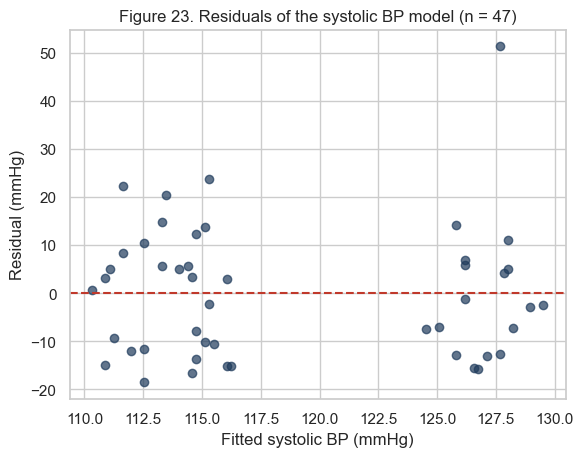

In [454]:
# Figure 23: residuals (what the model missed) against fitted values
plt.scatter(sys_fitted, sys_resid, color="#1f3b5c", alpha=0.7)
plt.axhline(0, color="#c0392b", linestyle="--")
plt.title(f"Figure 23. Residuals of the systolic BP model (n = {sys_n})")
plt.xlabel("Fitted systolic BP (mmHg)")
plt.ylabel("Residual (mmHg)")
plt.savefig("outputs/figures/fig23_residuals_systolic.png", dpi=200, bbox_inches="tight")
plt.show()

In [455]:
# Sensitivity check on the same participants: unadjusted vs age-adjusted sex difference, and without the single highest reading
def sex_difference(data, label, adjust=True):
    women = data.loc[data["sex"] == "F", "systolic_bp"]
    men = data.loc[data["sex"] == "M", "systolic_bp"]

    row = [
        label,
        len(data),
        men.median() - women.median(),
        stats.mannwhitneyu(men, women).pvalue,
        men.mean() - women.mean()
    ]

    if adjust:
        adjusted = fit_ols("systolic_bp", data)[0].loc["male (vs female)"]
        row += [
            adjusted["coefficient"],
            adjusted["ci_low"],
            adjusted["ci_high"]
        ]
    else:
        row += [np.nan, np.nan, np.nan]

    return row


complete = df.dropna(subset=["age"])
top_row = complete["systolic_bp"].idxmax()
without_top = complete.drop(index=top_row)

sensitivity_table = pd.DataFrame([
    sex_difference(df, "All 50 participants", adjust=False),
    sex_difference(complete, "47 with known age"),
    sex_difference(without_top, "Highest reading removed")
], columns=[
    "analysis",
    "n_rows",
    "median_diff_M_minus_F",
    "p_mann_whitney",
    "mean_diff_unadjusted",
    "adjusted_coef_male",
    "ci_low",
    "ci_high"
])

sensitivity_table.round(3)


,analysis,n_rows,median_diff_M_minus_F,p_mann_whitney,mean_diff_unadjusted,adjusted_coef_male,ci_low,ci_high
0,All 50 participants,50,12.0,0.002,14.747,NaN,NaN,NaN
1,47 with known age,47,11.5,0.008,13.414,13.631,5.092,22.170
2,Highest reading removed,46,11.0,0.015,10.355,10.536,3.278,17.793


In [456]:
# Model 2: diastolic blood pressure
dia_table, dia_fitted, dia_resid, dia_r2, dia_n = fit_ols("diastolic_bp")
dia_table.round(3)

,coefficient,std_error,t,p_value,ci_low,ci_high
intercept,74.339,5.404,13.756,0.000,63.448,85.230
male (vs female),1.460,2.685,0.544,0.589,-3.952,6.872
age (per year),0.060,0.150,0.403,0.689,-0.241,0.362


In [457]:
# Model 3: blood glucose
glu_table, glu_fitted, glu_resid, glu_r2, glu_n = fit_ols("glucose_mgdl")
glu_table.round(3)

,coefficient,std_error,t,p_value,ci_low,ci_high
intercept,84.978,11.227,7.569,0.000,62.351,107.605
male (vs female),0.038,5.579,0.007,0.995,-11.206,11.282
age (per year),0.340,0.311,1.093,0.280,-0.287,0.966


### What the regression shows

**Sample:** The regression uses the 47 participants with a known numerical age (a complete-case analysis). The three participants whose exact ages were unspecified were excluded from these models.

**Systolic BP:** After adjusting for recorded age, the model estimated that men's systolic BP readings were approximately 13.6 mmHg higher than women's (95% CI: 5.1–22.2 mmHg; unadjusted regression p = 0.002). This regression was a supplementary analysis and was not included in the 13-test Holm correction family. Among these same 47 participants, the unadjusted difference in mean systolic BP was 13.4 mmHg. Adjusting for age therefore changed the estimated difference very little. This suggests that the recorded age differences alone do not explain the observed male–female association, although residual confounding and unmeasured factors remain possible.

The estimated age coefficient was −0.185 mmHg per year (95% CI: −0.660 to 0.291). The interval includes zero, so the model did not detect a clear linear association between age and systolic BP. This does not establish that no age association exists.

**How much is explained:** The model's R-squared was approximately 0.195. Sex and age together accounted for about 19.5% of the observed variation in systolic BP among these 47 participants. The remaining variation was not explained by these two variables in this model.

**Residual plot (Figure 23) and checks:** The residual plot shows the distribution of model errors around the fitted values. One observation, corresponding to the highest recorded systolic BP reading (179 mmHg), stands out from the others. The Shapiro–Wilk test also indicates evidence of non-normal residuals (p = 0.001). Conventional regression p-values and confidence intervals should therefore be interpreted cautiously, particularly given the small sample. The sensitivity analysis provides an additional check on whether the estimated sex difference changes when this observation is excluded. Residual plots and normality tests cannot, by themselves, establish that all model assumptions are satisfied.

**Sensitivity analysis:** On the 47 participants with known ages, the unadjusted median difference was 11.5 mmHg (Mann–Whitney p = 0.008). After removing the highest systolic reading, the median difference was 11.0 mmHg (p = 0.015), while the age-adjusted male coefficient decreased from 13.6 to approximately 10.5 mmHg (95% CI: 3.3–17.8). The estimated difference remained positive, suggesting that it was not entirely driven by the highest reading, although its magnitude changed. These sensitivity-analysis p-values are supplementary and were not included in the 13-test Holm correction.

**Diastolic BP and glucose:** The models did not detect clear associations between sex or age and either outcome. The confidence intervals for these coefficients included zero. This does not establish that the associations are absent.

**Cautions:** The model assumes a linear relationship between age and the outcome, independent observations and an appropriate residual variance structure. These assumptions are difficult to assess reliably with only 47 participants. Unmeasured factors, including weight, time of day, measurement device, the person taking the reading and recent physical activity, could also contribute to the observed differences. The findings remain exploratory associations, not evidence of causation.

In [458]:
# Key results gathered in one place, written by the code so the numbers always match the analysis
male_row = sex_tests.set_index("variable").loc["systolic_bp"]
print("KEY RESULTS")
print(f"- Systolic BP: median {male_row['median_female']:.0f} (women) vs {male_row['median_male']:.0f} (men); difference {male_row['median_diff_M_minus_F']:.0f} mmHg, 95% CI {male_row['diff_ci_low']:.0f} to {male_row['diff_ci_high']:.0f}; Mann-Whitney p = {male_row['p_mann_whitney']:.3f}.")
adj = sys_table.loc["male (vs female)"]
print(f"- After adjusting for age: men differ from women by {adj['coefficient']:.1f} mmHg, 95% CI {adj['ci_low']:.1f} to {adj['ci_high']:.1f}, p = {adj['p_value']:.3f}.")
print(f"- Tests that stay significant after Holm correction: {int(all_tests['significant_after_holm'].sum())} of {len(all_tests)}.")
print(f"- Smallest detectable difference (80% power) for men vs women: d = {smallest_d:.2f}.")

KEY RESULTS
- Systolic BP: median 114 (women) vs 126 (men); difference 12 mmHg, 95% CI 2 to 25; Mann-Whitney p = 0.002.
- After adjusting for age: men differ from women by 13.6 mmHg, 95% CI 5.1 to 22.2, p = 0.002.
- Tests that stay significant after Holm correction: 2 of 13.
- Smallest detectable difference (80% power) for men vs women: d = 0.82.


## What part 2 allows us to conclude

**Supported, as exploratory associations:** In these 50 participants, recorded systolic blood pressure was higher in men than in women, with a median difference of approximately 12 mmHg. The main Mann–Whitney comparison remained statistically significant after Holm correction. In a supplementary regression using the 47 participants with known ages, the estimated male–female difference remained positive after adjusting for age. It also remained positive when the highest systolic reading was excluded, although its estimated magnitude decreased. These additional analyses were exploratory and were not included in the 13-test Holm correction.

Systolic and diastolic BP readings also showed a moderate positive monotonic association, as expected because both values come from the same blood pressure measurement.

**Not detected:** The analysis did not detect statistically significant differences in glucose or diastolic BP between men and women, or corrected differences in the measured variables across locations. It also did not establish clear associations between age and the measured variables. These results do not prove that such differences or relationships are absent.

**Not claimed:** That sex causes higher blood pressure, that the same difference exists across the wider community, that any participant has hypertension or diabetes, or what proportion of the wider community has elevated readings.

**Why it matters for the field:** The main methodological lesson is that small, self-selected screening samples require careful interpretation. Report effect sizes and confidence intervals alongside p-values, account for multiple testing, examine the sensitivity of findings to individual observations, and state clearly what the data cannot establish.

## What this project shows

- **Data preparation (Part 1):** Raw screening records were inspected, cleaned in documented steps, validated and saved. All 50 participant records were retained, including records with unspecified numerical ages.
- **Statistical analysis (Part 2):** Systolic BP was higher among men than women in the main comparison, and this result remained significant after Holm correction. The positive association between systolic and diastolic BP also remained significant after correction.
- **Additional analysis:** The age-adjusted regression and sensitivity analysis provided supplementary evidence that the observed male–female systolic BP difference remained positive under those alternative analyses. These supplementary tests were not part of the Holm-corrected family.
- **Uncertainty:** Key medians and percentages were reported with confidence intervals. The small convenience sample limits precision and generalisability.
- **Data management:** The project includes a provenance record, schema, checked data dictionary, quality checks, file fingerprints, a reduced-disclosure summary and a synthetic twin.



## What this project shows

- **Data preparation (Part 1):** raw screening records were inspected, cleaned in documented steps, validated and saved, with no participant deleted.
- **Statistics (Part 2):** systolic blood pressure was higher in men than in women by about 12 mmHg, a result that held after adjusting for age, without the highest reading, and after Holm's correction across the 13 main tests. Nothing else was clearly detected, and with 50 people that means "not detected", not "absent".
- **Uncertainty:** the key medians and percentages in Part 2 come with intervals, and the intervals are wide.
- **Data management (Part 2):** the dataset has a provenance record, a schema, a checked data dictionary, quality checks, file fingerprints, a reduced-disclosure summary and a synthetic twin.


## Future work: roadmap areas that were deliberately not built

| Roadmap area | Why it is not done here | When it would be appropriate |
|---|---|---|
| **1. Machine learning** | 47 to 50 rows, one reading each, no outcome to predict and no separate data to test on. A model would memorise noise | A much larger dataset (hundreds to thousands), a clear outcome such as confirmed hypertension at follow-up, repeat measurements and an independent test set. Then: a simple baseline, cross-validation, calibration, honest evaluation |
| **2. Specialised fields** (time series, survival, causal inference, text, images, Bayesian methods) | No time dimension, no follow-up, no text or images, and no clear question that needs them | Follow-up measurements (time series or survival analysis), a trial or natural experiment (causal methods), or a specific question that a Bayesian model would answer better |
| **3. Deep learning and modern AI** (including SHAP and LIME) | Far too little data and no prediction task. Explaining a model that should not exist is misleading | A large, well-governed dataset and a validated clinical question. Language models are useful for documentation, never for entering real participant data into a public tool |
| **4. Deployment and MLOps** (FastAPI, Docker, Streamlit) | There is no validated model, no users and no clinical governance | A validated model, a data-protection assessment, clinical sign-off and a plan for monitoring. A referral application also needs clinical governance first |


## Responsible use

This is an educational and analytical project. It is not medical advice, not a diagnostic tool and has not been clinically validated. Participant names were replaced with codes, which is pseudonymisation and not full anonymisation. The Nigeria Data Protection Act 2023 applies to this kind of data, and nothing here claims full legal compliance.
